# Few-Samples HSI Classification with CNN & Transformer

**Author:** Alessandro Carotenuto  
**Student ID:** 1847282  
**Dataset:** Pavia University  
**Main Reference Paper:** [CNN-Transformer and Channel-Spatial Attention based network for hyperspectral image classification with few samples](https://www.sciencedirect.com/science/article/pii/S0893608025001625/pdfft?md5=230d33c76c4e035ccd0989aa0e02c9eb&pid=1-s2.0-S0893608025001625-main.pdf)  
**Github Repository:** [Github Repository](https://github.com/Alessandro-Carotenuto/Hyperspectral-Neural-Networks-Project)  
**Kaggle Run:** [Kaggle Versioned Training](https://www.kaggle.com/code/carotenutoalessandro/nn-project-few-samples-hsi-classification-cta-net?scriptVersionId=360167071) (this exact notebook without the results table, since it was not ran yet)

## Project aim

This project aims to classify land-cover pixels in a hyperspectral image using a **limited number of training examples** implementing **CTA-net**

Each input is a spatial-spectral patch centered on a pixel.
In parallel:
-  A CNN learns local multi scale features
-  A lightweight Transformer captures non-local context

*Channel-spatial attention* and *sample amplification* are incorporated and evaluated through ablations to identify effective configurations and isolate their contributions. The project also explores a l*earned pruning mask to reduce the number of input spectral bands*.

### Theoretical Context

Basically a **hyperspectral image** records each pixel across many spectral bands (portions of the electromagnetic spectre).
Since different materials reflect electromagnetic radiation differently, the spectrum describes the pixel’s material properties (in some way), while neighboring pixels provide spatial context. In few-shot classification, only a small number of labeled pixels are available, which makes overfitting a key challenge.

CTA-Net combines a CNN and a Transformert Their features are fused and refined by **channel-spatial attention**, which emphasizes informative channels and locations. 
The model **uses each patch to classify its center pixel**.

**Sample amplification** addresses the limited training data. This project also explores learned spectral-band pruning as an extension, measuring its trade-off between classification accuracy and inference cost.

The pruning branch predicts a sigmoid gate for each spectral band and uses a sparsity penalty to encourage fewer active bands. A **straight-through estimator** lets gradients pass through hard selection during training. After training, bands are ranked by their average gate value, the lowest-scoring target fraction is removed, and the compact model is fine-tuned using only the retained bands.

## Results and Analysis

The tables below summarize previously recorded ablations, they are historical results but can be reproduced. The evaluation cells below report the current experiment.
All the runs have a Split Seed = 42 and 10-training seeds (1496815513, 1940408339, 194592138, 628378136, 109688099, 2039541324, 1831162321, 1559800566, 469802734, 1660496806)
Those were randomly picked the first time and then fixed for accurate ablations.

#### Main Component Ablations

Each row removes one CTA-Net component: Sample Amplification (SA), the CNN-Transformer block (CT), or channel-spatial attention (CSA). Results are from the recorded 10-seed experiment on split 42.

| Configuration | SA | CT | CSA | OA | AA | Kappa |
|---|:---:|:---:|:---:|---:|---:|---:|
| CT + CSA, without SA | — | ✓ | ✓ | 84.10 ± 4.06% | 88.03 ± 2.13% | 79.68 ± 4.77% |
| CT + SA, without CSA | ✓ | ✓ | — | 87.57 ± 2.55% | 90.58 ± 1.44% | 83.95 ± 3.09% |
| Full CTA-Net: CT + CSA + SA | ✓ | ✓ | ✓ | 85.55 ± 4.36% | 89.00 ± 2.17% | 81.48 ± 5.23% |

#### Attention Head Ablation

Only the number of Transformer heads changes; the 4-head run is the reference.

| Heads | OA | AA | Kappa |
|---:|---:|---:|---:|
| 2 | 86.32 ± 3.22% | 89.80 ± 1.60% | 82.40 ± 3.78% |
| 4 (reference) | 85.55 ± 4.36% | 89.00 ± 2.17% | 81.48 ± 5.23% |
| 8 | **88.42 ± 2.67%** | **90.07 ± 1.28%** | **84.96 ± 3.21%** |
| 16 | 86.96 ± 2.82% | 88.95 ± 1.74% | 83.09 ± 3.43% |

#### Selected Single-Factor Ablations

Each row changes one setting from the 4-head reference.

| Factor | Setting | OA | AA | Kappa |
|---|---:|---:|---:|---:|
| Reference | Original settings, 4 heads | 85.55 ± 4.36% | 89.00 ± 2.17% | 81.48 ± 5.23% |
| FFN expansion | 2 | **87.02 ± 1.88%** | 89.54 ± 1.77% | **83.22 ± 2.43%** |
| CNN normalization | LayerNorm | **88.69 ± 1.83%** | 89.38 ± 0.98% | **85.18 ± 2.18%** |
| Input normalization | Z-score | 87.58 ± 2.46% | **90.77 ± 0.87%** | 83.99 ± 3.03% |
| Positional encoding | Conformer 1D | 85.60 ± 5.01% | 89.78 ± 1.72% | 81.63 ± 5.90% |
| Transformer dropout | 0.5 | 80.86 ± 8.29% | 84.44 ± 4.87% | 75.77 ± 9.81% |
| FFN residual scale | 2.0 | 87.00 ± 3.72% | 89.37 ± 1.72% | 83.21 ± 4.42% |
| Patch size | 11 × 11 | **87.64 ± 1.63%** | **89.90 ± 2.20%** | **83.96 ± 2.06%** |
| LR scheduler | Cosine annealing | 85.98 ± 3.38% | 89.16 ± 1.59% | 81.96 ± 4.04% |

#### Selected Configuration Combinations

These rows change multiple settings at once.

| Configuration | Split | OA | AA | Kappa |
|---|---:|---:|---:|---:|
| 8 heads (best single setting) | 42 | **88.42 ± 2.67%** | 90.07 ± 1.28% | **84.96 ± 3.21%** |
| 8 heads + Z-score | 42 | 87.56 ± 2.79% | **90.68 ± 1.24%** | 83.97 ± 3.46% |
| 8 heads + LayerNorm | 42 | 86.54 ± 2.48% | 89.60 ± 1.40% | 82.66 ± 2.96% |
| 8 heads + cosine annealing | 42 | 86.99 ± 3.18% | 89.28 ± 2.36% | 83.12 ± 4.10% |
| 8 heads + patch 11 × 11 | 42 | 87.36 ± 1.99% | 89.22 ± 1.65% | 83.61 ± 2.44% |
| 8 heads + patch 11 × 11 + Z-score | 42 | 86.33 ± 1.47% | 89.34 ± 0.95% | 82.35 ± 1.78% |
| 4 heads + LayerNorm + expansion 2 | 42 | 87.19 ± 2.03% | 89.18 ± 1.61% | 83.33 ± 2.58% |
| 4 heads + expansion 2 + residual scale 2 | 42 | 87.56 ± 1.62% | **90.30 ± 0.85%** | 83.88 ± 1.98% |
| Combined best settings | 42 | 85.09 ± 1.57% | 87.71 ± 1.23% | 80.73 ± 1.94% |
| Same combined settings | 1 | 78.51 ± 5.17% | 86.61 ± 2.12% | 73.12 ± 5.90% |

#### Pruning Ablations

The table reports the compact classifier after spectral-band pruning. The 0-epoch result measures transfer without compact-model fine-tuning; the other rows use 30 fine-tuning epochs. Results are from 10 training seeds on split 42.

| Heads | Pruning | Compact fine-tuning | OA | AA | Kappa |
|---:|---:|---:|---:|---:|---:|
| 4 | 5% | 30 epochs | 84.73 ± 4.28% | 87.91 ± 2.59% | 80.41 ± 5.23% |
| 8 | 5% | 30 epochs | 87.17 ± 2.32% | 88.96 ± 1.68% | 83.29 ± 2.92% |
| 4 | 20% | 0 epochs | 55.73 ± 8.40% | 59.84 ± 5.32% | 44.52 ± 8.70% |
| 4 | 20% | 30 epochs | 86.56 ± 2.16% | 88.05 ± 2.18% | 82.48 ± 2.64% |
| 8 | 20% | 30 epochs | 85.36 ± 4.34% | 88.99 ± 1.57% | 81.17 ± 5.11% |



## This Notebook's Results

This notebook runs the best configuration and runs an ablation for the model with 150 epochs + 30 fine tuned into a compact model and compares it towards the base model without spectal mask learning and re-trained from scratch for 180 epochs. Test results on Pavia University, split seed 42, over 5 training seeds. Values are mean ± sample standard deviation.

| Model | Test OA | Test AA | Kappa |
|---|---:|---:|---:|
| Full-band CTA-CSA, 103 bands, trained from scratch for 180 epochs | 88.47 ± 2.13% | 89.72 ± 1.56% | 84.96 ± 2.66% |
| Compact pruned model, 72 of 103 bands, 150 + 30 fine-tuning epochs | 86.05 ± 1.29% | 89.41 ± 0.92% | 82.05 ± 1.52% |
| **Paired difference, compact minus full-band** | **−2.42 ± 1.26 pp** | **−0.31 ± 2.24 pp** | **−2.92 ± 1.73 pp** |

**Paired** differences compare the two models on matching training seeds.
The training curves shown are just for the last fine tuning.

### How does it work?

This **Notebook** imports the other python modules and generates the splits, imports the datasets, calls the class to create the architecture depending on the configuration, it can be imported in **Kaggle**, see next

## Setup 

This cell actually handles the possibility of running this notebook inside **Kaggle** or **locally**  

**To run this locally, nothing is needed just notebook in the same folder as the .py files**
- If a comparison: compact pruned model vs unpruned is not necessary, just turn off the flag COMPARE_WITH_UNPRUNED while [*configurating the experiment*](#architecture-and-training-configuration)

To run this on Kaggle (like i did mostly):
- Create a new notebook on kaggle
- Import the **Pavia University dataset** as input, there are many uplaoded versions on kaggle like the one i used: [Here](https://www.kaggle.com/datasets/syamkakarla/pavia-university-hsi)  
- **Import** this notebook
- **Activate Internet Connection**
- **Configurate** the training
- **Run the training**

If it's on Kaggle, it will **clone** my repository and set up the paths

In [1]:
### Runtime and project source

from pathlib import Path
import importlib
import inspect
import subprocess
import sys
import numpy as np
import torch
import torch.nn as nn
from scipy.io import loadmat

# LOCATE PROJECT SOURCE
LOCAL_PROJECT_ROOT = Path.cwd().resolve()

REQUIRED_PROJECT_MODULES = (
    "data.py",
    "evaluation.py",
    "models.py",
    "plotting.py",
    "training.py",
    "utils.py",
)

KAGGLE_REPOSITORY_URL = (
    "https://github.com/Alessandro-Carotenuto/"
    "Hyperspectral-Neural-Networks-Project.git"
)

KAGGLE_PROJECT_ROOT = Path("/kaggle/working/project-source")
IS_KAGGLE = Path("/kaggle/input").is_dir()



def has_project_modules(directory):
    """RETURN TRUE IF ALL MODULES ARE PRESENT IN THE DIRECTORY"""
    return all((directory / name).is_file() for name in REQUIRED_PROJECT_MODULES)



def run_git(*arguments):
    """USING A SUBPROCESS TO RUN A GIT COMMAND"""
    return subprocess.run(
        ["git", *arguments],
        check=True,
        capture_output=True,
        text=True,
        timeout=180,
    )


def get_kaggle_project_root():
    """First Run for cloning the project source on Kaggle, then update it on subsequent runs
    
    Note to self: 
    -c is for running git commands in a specific directory, 
    --ff-only is for fast-forward only updates, 
    --depth 1 is for shallow cloning
    --branch main is for cloning the main branch."""


    if KAGGLE_PROJECT_ROOT.exists():
        run_git("-C", str(KAGGLE_PROJECT_ROOT),"pull", "--ff-only", "origin", "main")
    else:
        run_git("clone", "--depth", "1", "--branch", "main",KAGGLE_REPOSITORY_URL, str(KAGGLE_PROJECT_ROOT))

    if not has_project_modules(KAGGLE_PROJECT_ROOT):
        raise ModuleNotFoundError(f"MISSING MODULES FROM {KAGGLE_PROJECT_ROOT}.")
    return KAGGLE_PROJECT_ROOT


if IS_KAGGLE:
    source_root = get_kaggle_project_root()
else:
    source_root = LOCAL_PROJECT_ROOT
    if not has_project_modules(source_root):
        raise ModuleNotFoundError(
            f"Project modules were not found in {source_root}. "
            "Run the notebook with the project root as its working directory."
        )


# ADD PROJECT SOURCE TO PYTHON PATH
# SO I CAN IMPORT MODULES WITHOUT THE WHOLE PATH
source_root = source_root.resolve()
source_root_string = str(source_root)

if source_root_string in sys.path:
    sys.path.remove(source_root_string)
sys.path.insert(0, source_root_string)

# FOLDR TO SAVE OUTPUTS, MODELS, AND PLOTS
project_root = Path("/kaggle/working") if IS_KAGGLE else source_root


### Project imports


In [2]:
from data import (
    create_dataloaders,
    create_few_shot_split,
    create_patch_datasets,
    create_run_datasets,
    extract_patch,
    normalize_per_band,
    reflect_pad_spatially,
    split_counts_by_class,
)
from evaluation import (
    aggregate_classification_metrics,
    calculate_classification_metrics,
    build_classification_map,
    build_evaluation_report,
    evaluate_checkpoint,
    predict_classes,
    save_evaluation_report,
)
from models import (
    build_compact_pruned_model,
    build_model,
)
from plotting import (
    plot_classification_map,
    plot_confusion_matrix,
    plot_pruning_mask,
    plot_training_curves,
)
# Reload training after clone/pull so a live Kaggle kernel cannot keep old code.
if "training" in sys.modules:
    loaded_training_path = Path(
        getattr(sys.modules["training"], "__file__", "")
    ).resolve()
    try:
        loaded_training_path.relative_to(source_root.resolve())
    except ValueError:
        del sys.modules["training"]
importlib.invalidate_caches()
import training as training_module
training_module = importlib.reload(training_module)
required_parameters = {
    training_module.build_checkpoint_path: {"weight_decay"},
    training_module.fit_model: {"weight_decay", "pruning_controller"},
}
for function, required in required_parameters.items():
    if not required.issubset(inspect.signature(function).parameters):
        raise RuntimeError(
            f"Loaded stale training code from {training_module.__file__}. "
            "Restart the Kaggle session and rerun the setup cell."
        )
AdaptivePruningController = training_module.AdaptivePruningController
build_checkpoint_path = training_module.build_checkpoint_path
build_training_seeds = training_module.build_training_seeds
configure_reproducibility = training_module.configure_reproducibility
fit_model = training_module.fit_model
from utils import (
    ConformerCNNNormalization,
    DataSplitType,
    InputNormalization,
    LRSchedulingType,
    ModelArchitecture,
    PatchSize,
    PaviaClass,
    SampleAmplificationMode,
    SplitName,
    TrainingSeedMode,
    TransformerPositionEncoding,
)



### DATASET PATHS AND LOADING


Locate Pavia University data on Kaggle or in the local `data/raw` directory.


In [3]:
# FIND PAVIA FILES ON KAGGLE 
if IS_KAGGLE:
    kaggle_input_dir = Path("/kaggle/input")
    cube_matches = list(kaggle_input_dir.rglob("PaviaU.mat"))
    ground_truth_matches = list(kaggle_input_dir.rglob("PaviaU_gt.mat"))

    if len(cube_matches) != 1 or len(ground_truth_matches) != 1:
        raise FileNotFoundError(
            "Expected one PaviaU.mat and one PaviaU_gt.mat under "
            f"{kaggle_input_dir}; found {len(cube_matches)} and "
            f"{len(ground_truth_matches)}. Attach the Pavia dataset."
        )

    cube_path = cube_matches[0]
    ground_truth_path = ground_truth_matches[0]

# FIND PAVIA FILES LOCALLY
else:
    local_data_dir = project_root / "data" / "raw"
    cube_path = local_data_dir / "PaviaU.mat"
    ground_truth_path = local_data_dir / "PaviaU_gt.mat"

for input_path in (cube_path, ground_truth_path):
    if not input_path.is_file():
        raise FileNotFoundError(f"Dataset file not found: {input_path}")


# LOAD MATLAB FILES
cube = loadmat(cube_path)["paviaU"]
ground_truth = loadmat(ground_truth_path)["paviaU_gt"]
print("Cube:", cube.shape)
print("Ground truth:", ground_truth.shape)


Cube: (610, 340, 103)
Ground truth: (610, 340)


### ARCHITECTURE AND TRAINING CONFIGURATION


In [4]:
MODEL_VARIANT = "FINAL TRAINING"
# DATA AND FEW-SHOT SPLIT

SPLIT_SEED = 42
DATA_SPLIT_TYPE = DataSplitType.RANDOM 

# DATA SPLIT TYPES AND MEANING:
# -RANDOM:                      random pixel split; patches can overlap spatially
# -RANDOM_NO_CENTER_OVERLAP:    exclude test centers inside training patches
# -RANDOM_NO_OVERLAP:           keep training and test patch footprints separate

TRAIN_SAMPLES_PER_CLASS = 10
VALIDATION_SAMPLES_PER_CLASS = 5

NUM_CLASSES = len(PaviaClass) - 1 #Exclude the UNLABELED class from the count of classes

LABELED_CLASS_IDS = tuple(
    int(label) for label in PaviaClass
    if label != PaviaClass.UNLABELED
)

class_names = {int(label): label.display_name for label in PaviaClass}

# PAVIA CLASS OPTIONS AND MEANING:
# IT ONLY CONTAINS THE CLASSES THAT ARE LABELED IN THE DATASET, EXCLUDING UNLABELED CLASS
# POSSIBLE TO EXCLUDE OTHERS ADDING THEM TO THE IF CONDITION 
# -UNLABELED (0):                 unlabeled pixel excluded from classification
# -ASPHALT (1):                   asphalt surface
# -MEADOWS (2):                   meadow vegetation
# -GRAVEL (3):                    gravel surface
# -TREES (4):                     tree cover
# -PAINTED_METAL_SHEETS (5):      painted metal roof
# -BARE_SOIL (6):                 bare soil
# -BITUMEN (7):                   bitumen surface
# -SELF_BLOCKING_BRICKS (8):      self-blocking brick surface
# -SHADOWS (9):                   shaded areas


# PATCHES SIZES AND PREPROCESSING

PATCH_SIZE = PatchSize.PAPER

# PATCH SIZE OPTIONS AND MEANING:
# -SMALLEST (7):                  7-by-7 spatial patch
# -SMALL (11):                    11-by-11 spatial patch
# -PAPER (15):                    15-by-15 spatial patch used in the paper
# -LARGE (19):                    19-by-19 spatial patch
# -LARGEST (23):                  23-by-23 spatial patch

PATCH_RADIUS = int(PATCH_SIZE) // 2

INPUT_NORMALIZATION = InputNormalization.MIN_MAX

# INPUT NORMALIZATION OPTIONS AND MEANING:
# -MIN_MAX:                       scales each spectral band to [0, 1]
# -Z_SCORE:                       centers each band at 0 and scales to unit standard deviation

# MODEL ARCHITECTURE
# Selects the classifier and its feature, Transformer, and pruning settings
# Pruning settings are used only by the experimental pruning architecture

ARCHITECTURE = ModelArchitecture.CNN_TRANSFORMER_CSA_BAND_PRUNING

MODEL_NAME = ARCHITECTURE.display_name
RUN_NAME = "full"

# MODEL ARCHITECTURE OPTIONS AND MEANING:
# -CNN_CSA:                                       multiscale CNN with channel-spatial attention
# -CNN_TRANSFORMER:                               parallel CNN and Transformer branches
# -CNN_TRANSFORMER_CSA:                           CNN-Transformer with channel-spatial attention
# -CNN_TRANSFORMER_CSA_BAND_PRUNING:              adds adaptive raw-band gates and pruning

FEATURE_CHANNELS = 128
TRANSFORMER_HEADS = 8
TRANSFORMER_FFN_EXPANSION = 4
TRANSFORMER_FFN_RESIDUAL_SCALE = 0.5

TRANSFORMER_POSITION_ENCODING = TransformerPositionEncoding.LEARNED_2D

# TRANSFORMER POSITION ENCODING OPTIONS AND MEANING:
# -LEARNED_2D:                    learned relative bias over 2D patch offsets
# -CONFORMER_1D:                  relative position encoding over flattened patch tokens, like the Conformer paper

TRANSFORMER_CNN_NORMALIZATION = ConformerCNNNormalization.BATCH_NORM

# CONFORMER CNN NORMALIZATION OPTIONS AND MEANING:
# -BATCH_NORM:                    normalizes activations across the batch
# -LAYER_NORM:                    normalizes activations across channels per sample

TRANSFORMER_DROPOUT = 0.1           

# PRUNING SETTINGS, if NO PRUNING WANTED, SET PRUNING_PERCENTAGE = 0.0 (default)

PRUNING_PERCENTAGE = 30.0           # Percentage of raw spectral bands to prune in the pruning architecture
PRUNING_GATE_SLOPE = 20.0           # Slope of the sigmoid function used to gate raw spectral bands in the pruning architecture
PRUNING_SPARSITY_WEIGHT = 0.001     # Weight of the sparsity loss term that encourages pruning in the pruning architecture
PRUNING_FINETUNE_EPOCHS = 30        # Set to 0 to skip compact-model fine-tuning
COMPARE_WITH_UNPRUNED = True      # Train and evaluate a full-band CTA-CSA baseline when enabled

# SAMPLE AMPLIFICATION
# Augments training patches; validation and test patches remain unchanged

SAMPLE_AMPLIFICATION_MODE = SampleAmplificationMode.CTA_NET

# SAMPLE AMPLIFICATION MODE OPTIONS AND MEANING:
# -DISABLED:                      uses the original training patches only
# -CTA_NET:                       adds noisy, rotated, and same-class summed patches

# Sample amplification settings for the CTA-Net augmentation, reasonable values
SA_CENTRAL_REGION_SIZE = 3
SA_GAUSSIAN_NOISE_STD = 0.04

# TRAINING AND OPTIMIZATION
# Controls the training duration, optimizer, learning rate, and saved reports

EPOCHS = 150                    #Matches the number of epochs used in the original paper for training the model
BASELINE_EPOCHS = EPOCHS + PRUNING_FINETUNE_EPOCHS

LEARNING_RATE = 0.00008
WEIGHT_DECAY = 0.0

LR_SCHEDULING = LRSchedulingType.FIXED

# LR SCHEDULING TYPE OPTIONS AND MEANING:
# -FIXED:                         keeps the learning rate constant
# -COSINEANNEALING:               reduces the learning rate with a cosine schedule

EVALUATION_PROGRESS_EVERY = 100
SAVE_EVALUATION_REPORT = True

# TRAINING SEEDS
# Choose one fixed seed or a fixed/random list for repeated runs
# Reuse a printed seed list to compare configurations with the same seeds

TRAINING_SEED_MODE = TrainingSeedMode.MULTI_FIXED_TRAIN_SEED

# TRAINING SEED MODE OPTIONS AND MEANING:
# -ONE_FIXED_TRAIN_SEED:          runs once with TRAINING_SEED_FIXED
# -MULTI_FIXED_TRAIN_SEED:        reuses the seed list in TRAINING_SEEDS_FIXED
# -MULTI_RANDOM_TRAIN_SEED:       generates a fresh random seed list

TRAINING_SEED_FIXED = 100
NUM_SEEDS = 5
TRAINING_SEEDS_FIXED = [
    1496815513,
    1940408339,
    194592138,
    628378136,
    109688099,
    # 2039541324,
    # 1831162321,
    # 1559800566,
    # 469802734,
    # 1660496806,
]

# RUNTIME
# Sets batch loading and selects a GPU when available, otherwise the CPU
BATCH_SIZE = 32
NUM_WORKERS = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")



### Configuration summary


In [5]:
print("Cube:", cube_path)
print("Ground truth:", ground_truth_path)
print("Runtime:", "Kaggle" if IS_KAGGLE else "local")
print("Patch size:", int(PATCH_SIZE))
print("Architecture:", ARCHITECTURE.display_name)
print("Model variant:", MODEL_VARIANT)
if ARCHITECTURE.uses_transformer:
    print("Transformer heads:", TRANSFORMER_HEADS)
    print(
        "Transformer FFN residual scale:",
        TRANSFORMER_FFN_RESIDUAL_SCALE,
    )
    print(
        "Transformer position encoding:",
        TRANSFORMER_POSITION_ENCODING.value,
    )
    print(
        "Transformer CNN normalization:",
        TRANSFORMER_CNN_NORMALIZATION.value,
    )
print("Split seed:", SPLIT_SEED)
print("Data split:", DATA_SPLIT_TYPE.value)
training_seeds = build_training_seeds(
    TRAINING_SEED_MODE,
    TRAINING_SEED_FIXED,
    NUM_SEEDS,
    fixed_seeds=TRAINING_SEEDS_FIXED,
)
print("Training seed mode:", TRAINING_SEED_MODE.value)
print("Training seeds:", training_seeds)
print(f"TRAINING_SEEDS_FIXED = {training_seeds}")
print("Selected device:", DEVICE)
print("Input normalization:", INPUT_NORMALIZATION.value)
print("Pruning gate slope:", PRUNING_GATE_SLOPE)
print("Pruning sparsity weight:", PRUNING_SPARSITY_WEIGHT)
print("Pruning percentage:", PRUNING_PERCENTAGE)
print("Compact pruning fine-tune epochs:", PRUNING_FINETUNE_EPOCHS)
print("Sample amplification:", SAMPLE_AMPLIFICATION_MODE.value)


Cube: /kaggle/input/datasets/syamkakarla/pavia-university-hsi/PaviaU.mat
Ground truth: /kaggle/input/datasets/syamkakarla/pavia-university-hsi/PaviaU_gt.mat
Runtime: Kaggle
Patch size: 15
Architecture: CNN-Transformer-CSA-Band-Pruning
Model variant: FINAL TRAINING
Transformer heads: 8
Transformer FFN residual scale: 0.5
Transformer position encoding: learned_2d
Transformer CNN normalization: batch_norm
Split seed: 42
Data split: random
Training seed mode: multi_fixed_train_seed
Training seeds: [1496815513, 1940408339, 194592138, 628378136, 109688099]
TRAINING_SEEDS_FIXED = [1496815513, 1940408339, 194592138, 628378136, 109688099]
Selected device: cuda
Input normalization: min_max
Pruning gate slope: 20.0
Pruning sparsity weight: 0.001
Pruning percentage: 30.0
Compact pruning fine-tune epochs: 30
Sample amplification: cta_net


## SPLIT GENERATION, DATALOADING, PREPROCESSING


### GENERATE AND SAVE FEW-SHOT COORDINATE SPLIT


In [6]:
split_tables = create_few_shot_split(
    ground_truth,
    LABELED_CLASS_IDS,
    seed=SPLIT_SEED,
    train_samples_per_class=TRAIN_SAMPLES_PER_CLASS,
    validation_samples_per_class=VALIDATION_SAMPLES_PER_CLASS,
    split_type=DATA_SPLIT_TYPE,
    patch_radius=PATCH_RADIUS,
)
split_counts = split_counts_by_class(
    split_tables, LABELED_CLASS_IDS
)

for label in LABELED_CLASS_IDS:
    counts_for_label = split_counts[label]
    print(
        f"{label}: {class_names[label]} - "
        f"train {counts_for_label['train']}, "
        f"validation {counts_for_label['validation']}, "
        f"test {counts_for_label['test']}, "
        f"excluded {counts_for_label['excluded']}"
    )

expected_train_samples = len(split_tables[SplitName.TRAIN.value])
expected_validation_samples = len(
    split_tables[SplitName.VALIDATION.value]
)
expected_test_samples = len(split_tables[SplitName.TEST.value])

split_directory = project_root / "data" / "splits" / f"seed_{SPLIT_SEED}"
split_directory.mkdir(parents=True, exist_ok=True)
split_suffix = (
    ""
    if DATA_SPLIT_TYPE == DataSplitType.RANDOM
    else f"_{DATA_SPLIT_TYPE.value}"
)
for split_name, split_table in split_tables.items():
    split_path = split_directory / f"{split_name}{split_suffix}.csv"
    np.savetxt(
        split_path,
        split_table,
        fmt="%d",
        delimiter=",",
        header="row,column,label",
        comments="",
    )
    print(f"Saved {len(split_table)} samples to {split_path}")


1: Asphalt - train 10, validation 5, test 6616, excluded 0
2: Meadows - train 10, validation 5, test 18634, excluded 0
3: Gravel - train 10, validation 5, test 2084, excluded 0
4: Trees - train 10, validation 5, test 3049, excluded 0
5: Painted metal sheets - train 10, validation 5, test 1330, excluded 0
6: Bare Soil - train 10, validation 5, test 5014, excluded 0
7: Bitumen - train 10, validation 5, test 1315, excluded 0
8: Self-Blocking Bricks - train 10, validation 5, test 3667, excluded 0
9: Shadows - train 10, validation 5, test 932, excluded 0
Saved 90 samples to /kaggle/working/data/splits/seed_42/train.csv
Saved 45 samples to /kaggle/working/data/splits/seed_42/validation.csv
Saved 42641 samples to /kaggle/working/data/splits/seed_42/test.csv
Saved 0 samples to /kaggle/working/data/splits/seed_42/excluded.csv


### INPUT NORMALIZATION

In [7]:
# Check output shape, dtype, and the selected per-band normalization.
normalized_cube = normalize_per_band(cube, INPUT_NORMALIZATION)
assert normalized_cube.shape == cube.shape
assert normalized_cube.dtype == np.float32
assert not np.shares_memory(normalized_cube, cube)

if INPUT_NORMALIZATION == InputNormalization.MIN_MAX:
    assert np.allclose(normalized_cube.min(axis=(0, 1)), 0.0)
    assert np.allclose(normalized_cube.max(axis=(0, 1)), 1.0)
elif INPUT_NORMALIZATION == InputNormalization.Z_SCORE:
    assert np.allclose(normalized_cube.mean(axis=(0, 1)), 0.0, atol=1e-5)
    assert np.allclose(normalized_cube.std(axis=(0, 1)), 1.0, atol=1e-5)


### Reflect Padding

In [8]:
# Check padding adds the expected border and preserves the original cube.
padded_cube = reflect_pad_spatially(normalized_cube, PATCH_RADIUS)
expected_padded_shape = (
    normalized_cube.shape[0] + 2 * PATCH_RADIUS,
    normalized_cube.shape[1] + 2 * PATCH_RADIUS,
    normalized_cube.shape[2],
)
restored_normalized_cube = padded_cube[PATCH_RADIUS:-PATCH_RADIUS, PATCH_RADIUS:-PATCH_RADIUS, :]
assert padded_cube.shape == expected_padded_shape
assert padded_cube.dtype == normalized_cube.dtype
assert np.array_equal(restored_normalized_cube, normalized_cube)


### PyTorch Patch Dataset

This portion of the code reads the CSV file with the saved split and from the normalized and padded data, estracts patch of the wanted size, adjust for model class logits.

We also convert numeric types to float32 and we use *ascontigousarray* for efficiency

In [9]:
datasets = create_patch_datasets(padded_cube, split_tables, PATCH_SIZE, NUM_CLASSES)
train_dataset = datasets[SplitName.TRAIN.value]
validation_dataset = datasets[SplitName.VALIDATION.value]
test_dataset = datasets[SplitName.TEST.value]

example_patch, _ = train_dataset[0]
example_row, example_column = train_dataset.coordinates[0]

assert len(train_dataset) == expected_train_samples
assert len(validation_dataset) == expected_validation_samples
assert len(test_dataset) == expected_test_samples
expected_center_spectrum = torch.from_numpy(normalized_cube[example_row, example_column, :])
assert torch.equal(example_patch[:, PATCH_RADIUS, PATCH_RADIUS], expected_center_spectrum)


### PyTorch DataLoaders

In [10]:
dataloaders = create_dataloaders(
    datasets,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    training_seed=training_seeds[0],
)

train_loader = dataloaders[SplitName.TRAIN.value]
validation_loader = dataloaders[SplitName.VALIDATION.value]
test_loader = dataloaders[SplitName.TEST.value]

batch_patches, batch_targets = next(iter(validation_loader))
expected_batch_size = min(BATCH_SIZE, len(validation_dataset))
train_class_counts = np.bincount(train_dataset.targets, minlength=NUM_CLASSES)

expected_batch_shape = (
    expected_batch_size, cube.shape[2], int(PATCH_SIZE), int(PATCH_SIZE)
)
assert batch_patches.shape == expected_batch_shape
assert batch_targets.shape == (expected_batch_size,)
assert batch_patches.dtype == torch.float32
assert batch_targets.dtype == torch.long
assert batch_targets.min() >= 0
assert batch_targets.max() < NUM_CLASSES
assert np.array_equal(train_class_counts, np.full(NUM_CLASSES, TRAIN_SAMPLES_PER_CLASS))

print("Batches per epoch:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))


Batches per epoch: 3
Validation batches: 2
Test batches: 1333


## Model Architecture

### CNN, TRANSFORMER, CT AND CSA BLOCKS

The CNN branch returns only its fused multiscale features. The single CT residual is applied after CNN-Transformer fusion, as shown in the paper. For spatial attention, this notebook follows the detailed text in Section 2.4: an extrema branch (`max`, `min`) and a distribution branch (`mean`, `std`) use `5 x 5` convolutions and PReLU, followed by concatenation and a `1 x 1` fusion convolution. Every block preserves `(B, C, H, W)`.

### Network Creation

In [11]:
MODEL_ARGUMENTS = {
    "input_channels": cube.shape[2],
    "feature_channels": FEATURE_CHANNELS,
    "num_classes": NUM_CLASSES,
    "patch_size": PATCH_SIZE,
    "transformer_heads": TRANSFORMER_HEADS,
    "transformer_expansion_factor": TRANSFORMER_FFN_EXPANSION,
    "transformer_dropout": TRANSFORMER_DROPOUT,
    "transformer_ffn_residual_scale": TRANSFORMER_FFN_RESIDUAL_SCALE,
    "transformer_position_encoding": TRANSFORMER_POSITION_ENCODING,
    "transformer_cnn_normalization": TRANSFORMER_CNN_NORMALIZATION,
    "pruning_gate_slope": PRUNING_GATE_SLOPE,
    "pruning_sparsity_weight": PRUNING_SPARSITY_WEIGHT,
    "pruning_percentage": PRUNING_PERCENTAGE,
}


def build_configured_model():
    model = build_model(ARCHITECTURE, **MODEL_ARGUMENTS)
    return model



### Forward and Backward Sanity Check

In [12]:
# ONE TRAINING PATCH FOR EACH CLASS

sanity_indices = [
    np.flatnonzero(train_dataset.targets == class_index)[0]
    for class_index in range(NUM_CLASSES)
]
sanity_samples = [train_dataset[int(index)] for index in sanity_indices]
sanity_patches = torch.stack([sample[0] for sample in sanity_samples])
sanity_targets = torch.stack([sample[1] for sample in sanity_samples])

# RUN ONE FORWARD AND BACKWARD PASS TO CHECK GRADIENTS
torch.manual_seed(training_seeds[0])
sanity_model = build_configured_model()
sanity_model.train()
criterion = nn.CrossEntropyLoss()
sanity_logits = sanity_model(sanity_patches)
sanity_loss = criterion(sanity_logits, sanity_targets)
sanity_loss.backward()

gradients = [p.grad for p in sanity_model.parameters() if p.grad is not None]
gradient_norm = sum(gradient.norm().item() for gradient in gradients)

# CHECK CLASS ORDER, OUTPUT SHAPE, LOSS, AND GRADIENTS
assert torch.equal(sanity_targets, torch.arange(NUM_CLASSES))
assert sanity_logits.shape == (NUM_CLASSES, NUM_CLASSES)
assert torch.isfinite(sanity_loss)
assert gradients
assert all(torch.isfinite(gradient).all() for gradient in gradients)
assert gradient_norm > 0

sanity_model.zero_grad(set_to_none=True)
print("Forward/backward check passed; gradient norm:", gradient_norm)


Forward/backward check passed; gradient norm: 14.471185368738134


## Model Training


### RUN METADATA AND CHECKPOINT PATHS

In [13]:
# PREPARE MODEL ARGUMENTS FOR THE SAVED REPORT
MODEL_ARGUMENTS_FOR_REPORT = {
    **MODEL_ARGUMENTS,
    "patch_size": int(PATCH_SIZE),
    "transformer_position_encoding": TRANSFORMER_POSITION_ENCODING.value,
    "transformer_cnn_normalization": TRANSFORMER_CNN_NORMALIZATION.value,
}

# CHECKPOINT FILE NAMING OPTIONS
CHECKPOINT_DIRECTORY = project_root / "outputs" / "checkpoints"
CHECKPOINT_ARGUMENTS = {
    "architecture": ARCHITECTURE,
    "transformer_heads": TRANSFORMER_HEADS,
    "transformer_expansion_factor": TRANSFORMER_FFN_EXPANSION,
    "transformer_dropout": TRANSFORMER_DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "transformer_ffn_residual_scale": TRANSFORMER_FFN_RESIDUAL_SCALE,
    "transformer_position_encoding": TRANSFORMER_POSITION_ENCODING,
    "transformer_cnn_normalization": TRANSFORMER_CNN_NORMALIZATION,
    "pruning_gate_slope": PRUNING_GATE_SLOPE,
    "pruning_sparsity_weight": PRUNING_SPARSITY_WEIGHT,
    "pruning_percentage": PRUNING_PERCENTAGE,
    "input_normalization": INPUT_NORMALIZATION,
    "model_variant": MODEL_VARIANT,
    "run_name": RUN_NAME,
    "patch_size": PATCH_SIZE,
    "epochs": EPOCHS,
    "feature_channels": FEATURE_CHANNELS,
    "scheduling_type": LR_SCHEDULING,
    "split_seed": SPLIT_SEED,
    "split_type": DATA_SPLIT_TYPE,
    "sample_amplification_mode": SAMPLE_AMPLIFICATION_MODE,
}

# CONFIGURATION SAVED WITH EACH CHECKPOINT AND REPORT
BASE_EXPERIMENT_CONFIGURATION = {
    "dataset": "Pavia University",
    "model": MODEL_NAME,
    "architecture": ARCHITECTURE.value,
    "model_variant": MODEL_VARIANT,
    "split_seed": SPLIT_SEED,
    "data_split_type": DATA_SPLIT_TYPE.value,
    "model_arguments": MODEL_ARGUMENTS_FOR_REPORT,
    "pruning_finetune_epochs": (
        PRUNING_FINETUNE_EPOCHS
        if ARCHITECTURE.uses_adaptive_pruning
        else 0
    ),
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "lr_scheduling": LR_SCHEDULING.value,
    "epochs_requested": EPOCHS,
    "normalization": INPUT_NORMALIZATION.value,
    "padding": "reflect",
    "run_mode": RUN_NAME,
}

RUN_CONFIGURATIONS = []

for training_seed in training_seeds:
    RUN_CONFIGURATIONS.append(
        {
            "training_seed": training_seed,
            "checkpoint_path": build_checkpoint_path(
                CHECKPOINT_DIRECTORY,
                **CHECKPOINT_ARGUMENTS,
                training_seed=training_seed,
            ),
            "configuration": {
                **BASE_EXPERIMENT_CONFIGURATION,
                "training_seed_mode": TRAINING_SEED_MODE.value,
                "training_seed": training_seed,
            },
        }
    )


### Model Training

In [14]:
# Train one pruning run per seed and, optionally, a full-band baseline.

training_runs = []
baseline_training_runs = []

for run_index, run_configuration in enumerate(RUN_CONFIGURATIONS, start=1):
    training_seed = run_configuration["training_seed"]
    print(
        f"\n=== Training run {run_index}/{len(training_seeds)} "
        f"| seed {training_seed} ==="
    )
    configure_reproducibility(training_seed)

    run_datasets = create_run_datasets(
        datasets,
        sample_amplification_mode=SAMPLE_AMPLIFICATION_MODE,
        training_seed=training_seed,
        central_region_size=SA_CENTRAL_REGION_SIZE,
        gaussian_noise_standard_deviation=SA_GAUSSIAN_NOISE_STD,
    )
    run_train_dataset = run_datasets[SplitName.TRAIN.value]
    print("Training samples for this run:", len(run_train_dataset))
    run_dataloaders = create_dataloaders(
        run_datasets,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        training_seed=training_seed,
    )

    model = build_configured_model().to(DEVICE)
    checkpoint_path = run_configuration["checkpoint_path"]
    experiment_configuration = run_configuration["configuration"]
    experiment_configuration["sample_amplification"] = getattr(
        run_train_dataset,
        "amplification_metadata",
        {"mode": SampleAmplificationMode.DISABLED.value},
    )
    pruning_controller = (
        AdaptivePruningController(model)
        if ARCHITECTURE.uses_adaptive_pruning
        else None
    )
    training_result = fit_model(
        model,
        run_dataloaders[SplitName.TRAIN.value],
        run_dataloaders[SplitName.VALIDATION.value],
        DEVICE,
        epochs=EPOCHS,
        learning_rate=LEARNING_RATE,
        scheduling_type=LR_SCHEDULING,
        weight_decay=WEIGHT_DECAY,
        checkpoint_path=checkpoint_path,
        checkpoint_metadata=experiment_configuration,
        pruning_controller=pruning_controller,
    )

    mask_checkpoint_path = checkpoint_path
    if ARCHITECTURE.uses_adaptive_pruning:
        mask_checkpoint = torch.load(
            mask_checkpoint_path, map_location=DEVICE, weights_only=False
        )
        model.load_state_dict(mask_checkpoint["model_state_dict"])
        selected_band_indices = torch.as_tensor(
            mask_checkpoint["selected_band_indices"], dtype=torch.long
        )
        mean_band_gates = torch.as_tensor(mask_checkpoint["mean_band_gates"])
        experiment_configuration.update({
            "pruned_band_count": len(selected_band_indices),
            "selected_band_indices": selected_band_indices.tolist(),
            "mean_band_gates": mean_band_gates.tolist(),
            "pruning_finetune_epochs": PRUNING_FINETUNE_EPOCHS,
        })
        print("Retained spectral bands:", len(selected_band_indices), "/", cube.shape[2])
        print("Pruning target (%):", PRUNING_PERCENTAGE)
        gate_quantiles = np.quantile(
            mean_band_gates.numpy(), [0, .1, .25, .5, .75, .9, 1]
        )
        print(
            "Mean gate quantiles [min, 10%, 25%, 50%, 75%, 90%, max]:",
            gate_quantiles.round(4).tolist(),
        )

        if PRUNING_FINETUNE_EPOCHS > 0:
            compact_model = build_compact_pruned_model(
                model, selected_band_indices
            ).to(DEVICE)
            compact_checkpoint_path = mask_checkpoint_path.with_name(
                mask_checkpoint_path.stem + "_compact.pt"
            )
            configure_reproducibility(training_seed)
            compact_checkpoint_metadata = {
                **experiment_configuration,
                "training_phase": "compact_pruning_finetune",
                "mask_checkpoint_path": str(mask_checkpoint_path),
            }
            training_result = fit_model(
                compact_model,
                run_dataloaders[SplitName.TRAIN.value],
                run_dataloaders[SplitName.VALIDATION.value],
                DEVICE,
                epochs=PRUNING_FINETUNE_EPOCHS,
                learning_rate=LEARNING_RATE,
                scheduling_type=LR_SCHEDULING,
                weight_decay=WEIGHT_DECAY,
                checkpoint_path=compact_checkpoint_path,
                checkpoint_metadata=compact_checkpoint_metadata,
            )
            checkpoint_path = compact_checkpoint_path
            del compact_model

    training_run = {
        "seed": training_seed,
        "configuration": experiment_configuration,
        "checkpoint_path": checkpoint_path,
        "mask_checkpoint_path": (
            mask_checkpoint_path if ARCHITECTURE.uses_adaptive_pruning else None
        ),
        "training_result": training_result,
    }
    training_runs.append(training_run)
    print("Best epoch:", training_result["best_epoch"])
    print("Best validation loss:", training_result["best_validation_loss"])
    print("Checkpoint saved to:", checkpoint_path)

    if COMPARE_WITH_UNPRUNED and ARCHITECTURE.uses_adaptive_pruning:
        configure_reproducibility(training_seed)
        baseline_model = build_model(
            ModelArchitecture.CNN_TRANSFORMER_CSA,
            **MODEL_ARGUMENTS,
        ).to(DEVICE)
        baseline_dataloaders = create_dataloaders(
            run_datasets,
            batch_size=BATCH_SIZE,
            num_workers=NUM_WORKERS,
            training_seed=training_seed,
        )
        baseline_checkpoint_arguments = {
            **CHECKPOINT_ARGUMENTS,
            "architecture": ModelArchitecture.CNN_TRANSFORMER_CSA,
            "run_name": f"{RUN_NAME}_unpruned",
            "pruning_percentage": 0.0,
            "epochs": BASELINE_EPOCHS,
        }
        baseline_checkpoint_path = build_checkpoint_path(
            CHECKPOINT_DIRECTORY,
            **baseline_checkpoint_arguments,
            training_seed=training_seed,
        )
        baseline_model_arguments = dict(MODEL_ARGUMENTS_FOR_REPORT)
        baseline_model_arguments["pruning_percentage"] = 0.0
        baseline_configuration = {
            **BASE_EXPERIMENT_CONFIGURATION,
            "model": ModelArchitecture.CNN_TRANSFORMER_CSA.display_name,
            "architecture": ModelArchitecture.CNN_TRANSFORMER_CSA.value,
            "training_seed_mode": TRAINING_SEED_MODE.value,
            "training_seed": training_seed,
            "comparison_role": "full_band_unpruned",
            "epochs_requested": BASELINE_EPOCHS,
            "pruning_finetune_epochs": 0,
            "model_arguments": baseline_model_arguments,
            "sample_amplification": experiment_configuration["sample_amplification"],
        }
        baseline_training_result = fit_model(
            baseline_model,
            baseline_dataloaders[SplitName.TRAIN.value],
            baseline_dataloaders[SplitName.VALIDATION.value],
            DEVICE,
            epochs=BASELINE_EPOCHS,
            learning_rate=LEARNING_RATE,
            scheduling_type=LR_SCHEDULING,
            weight_decay=WEIGHT_DECAY,
            checkpoint_path=baseline_checkpoint_path,
            checkpoint_metadata=baseline_configuration,
        )
        baseline_training_runs.append({
            "seed": training_seed,
            "configuration": baseline_configuration,
            "checkpoint_path": baseline_checkpoint_path,
            "training_result": baseline_training_result,
        })
        print(
            "Unpruned baseline best validation loss:",
            baseline_training_result["best_validation_loss"],
        )
        del baseline_model, baseline_dataloaders

    del model, run_dataloaders, run_train_dataset, run_datasets


=== Training run 1/5 | seed 1496815513 ===
Training samples for this run: 351
Epoch 001/150 | train loss 2.1202, acc 0.2422 | val loss 2.2136, acc 0.1111 | lr 8.00e-05
Epoch 010/150 | train loss 0.6784, acc 0.7806 | val loss 2.9624, acc 0.2667 | lr 8.00e-05
Epoch 020/150 | train loss 0.4827, acc 0.8319 | val loss 5.8768, acc 0.2444 | lr 8.00e-05
Epoch 030/150 | train loss 0.2690, acc 0.9031 | val loss 0.4884, acc 0.8222 | lr 8.00e-05
Epoch 040/150 | train loss 0.2837, acc 0.9060 | val loss 0.7229, acc 0.7333 | lr 8.00e-05
Epoch 050/150 | train loss 0.2564, acc 0.9031 | val loss 5.0578, acc 0.4000 | lr 8.00e-05
Epoch 060/150 | train loss 0.1688, acc 0.9373 | val loss 1.3837, acc 0.6222 | lr 8.00e-05
Epoch 070/150 | train loss 0.2420, acc 0.9088 | val loss 15.6419, acc 0.2889 | lr 8.00e-05
Epoch 080/150 | train loss 0.1140, acc 0.9687 | val loss 4.1998, acc 0.5333 | lr 8.00e-05
Epoch 090/150 | train loss 0.1137, acc 0.9687 | val loss 0.6635, acc 0.8000 | lr 8.00e-05
Epoch 100/150 | trai

### Training Curves

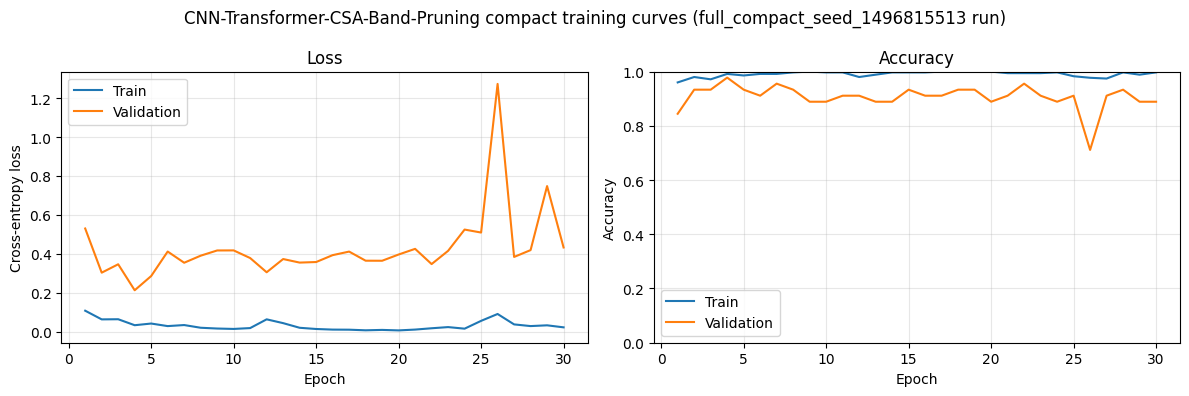

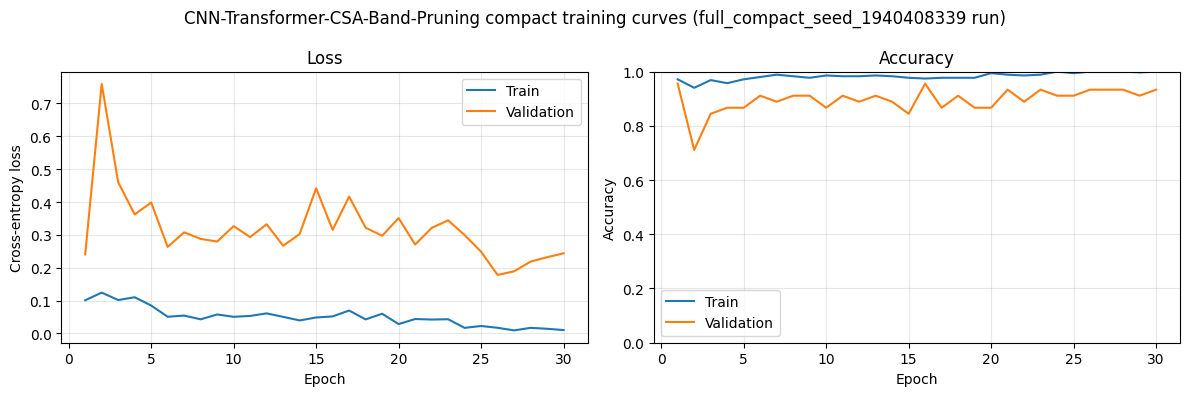

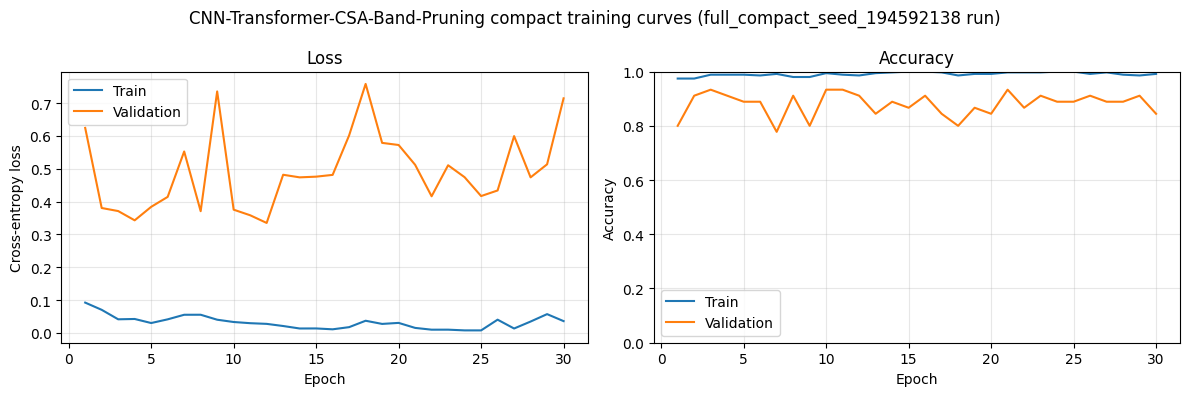

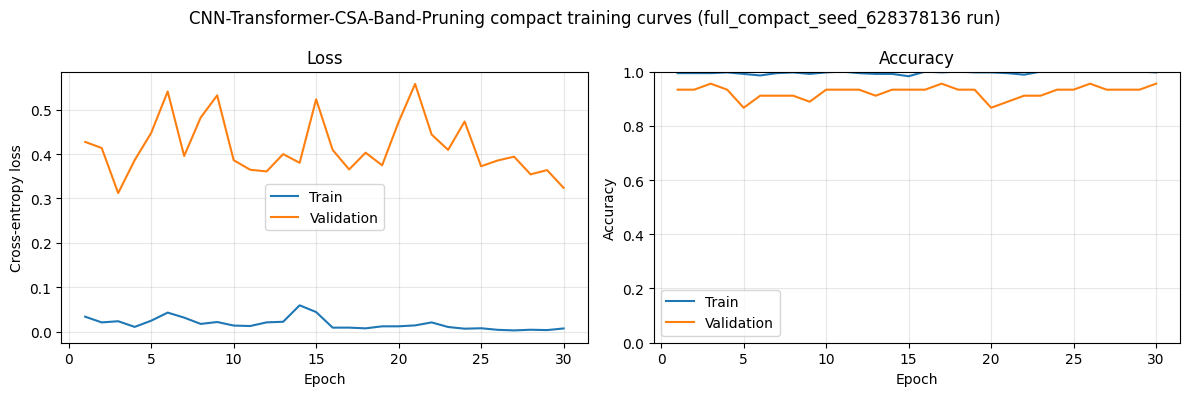

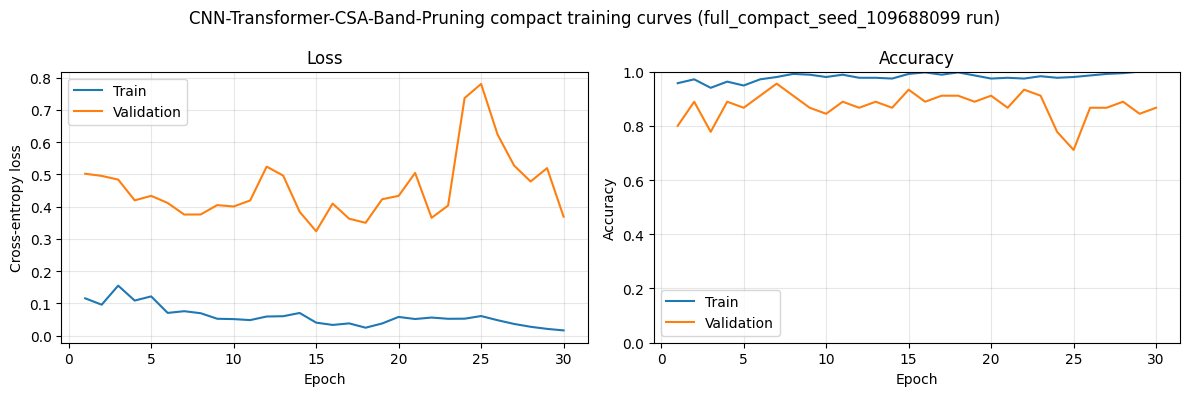

In [15]:
for run in training_runs:
    plot_training_curves(
        run["training_result"]["history"],
        f"{RUN_NAME}_compact_seed_{run['seed']}",
        f"{MODEL_NAME} compact" if ARCHITECTURE.uses_adaptive_pruning else MODEL_NAME,
    )

## Model Evaluation


=== Compact evaluation run 1/5 | seed 1496815513 ===
Compact test evaluation seed 1496815513: batch 1/1333 | samples 32/42641
Compact test evaluation seed 1496815513: batch 100/1333 | samples 3200/42641
Compact test evaluation seed 1496815513: batch 200/1333 | samples 6400/42641
Compact test evaluation seed 1496815513: batch 300/1333 | samples 9600/42641
Compact test evaluation seed 1496815513: batch 400/1333 | samples 12800/42641
Compact test evaluation seed 1496815513: batch 500/1333 | samples 16000/42641
Compact test evaluation seed 1496815513: batch 600/1333 | samples 19200/42641
Compact test evaluation seed 1496815513: batch 700/1333 | samples 22400/42641
Compact test evaluation seed 1496815513: batch 800/1333 | samples 25600/42641
Compact test evaluation seed 1496815513: batch 900/1333 | samples 28800/42641
Compact test evaluation seed 1496815513: batch 1000/1333 | samples 32000/42641
Compact test evaluation seed 1496815513: batch 1100/1333 | samples 35200/42641
Compact test eva

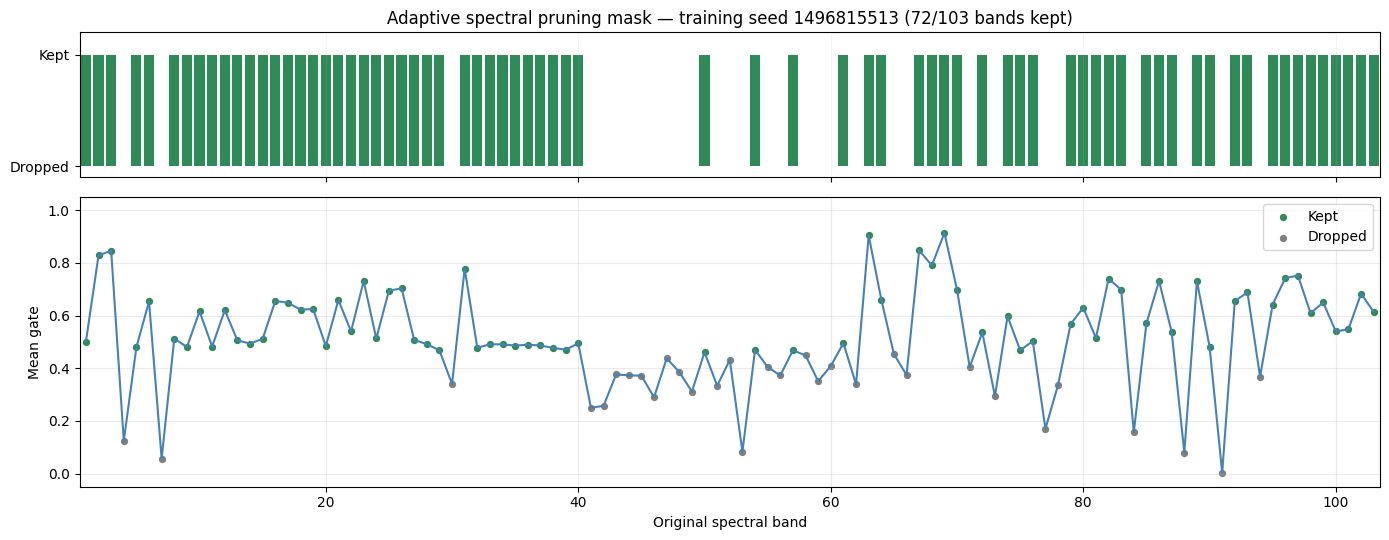

Selected checkpoint epoch: 4
Test predictions: 42641

=== Compact evaluation run 2/5 | seed 1940408339 ===
Compact test evaluation seed 1940408339: batch 1/1333 | samples 32/42641
Compact test evaluation seed 1940408339: batch 100/1333 | samples 3200/42641
Compact test evaluation seed 1940408339: batch 200/1333 | samples 6400/42641
Compact test evaluation seed 1940408339: batch 300/1333 | samples 9600/42641
Compact test evaluation seed 1940408339: batch 400/1333 | samples 12800/42641
Compact test evaluation seed 1940408339: batch 500/1333 | samples 16000/42641
Compact test evaluation seed 1940408339: batch 600/1333 | samples 19200/42641
Compact test evaluation seed 1940408339: batch 700/1333 | samples 22400/42641
Compact test evaluation seed 1940408339: batch 800/1333 | samples 25600/42641
Compact test evaluation seed 1940408339: batch 900/1333 | samples 28800/42641
Compact test evaluation seed 1940408339: batch 1000/1333 | samples 32000/42641
Compact test evaluation seed 1940408339: b

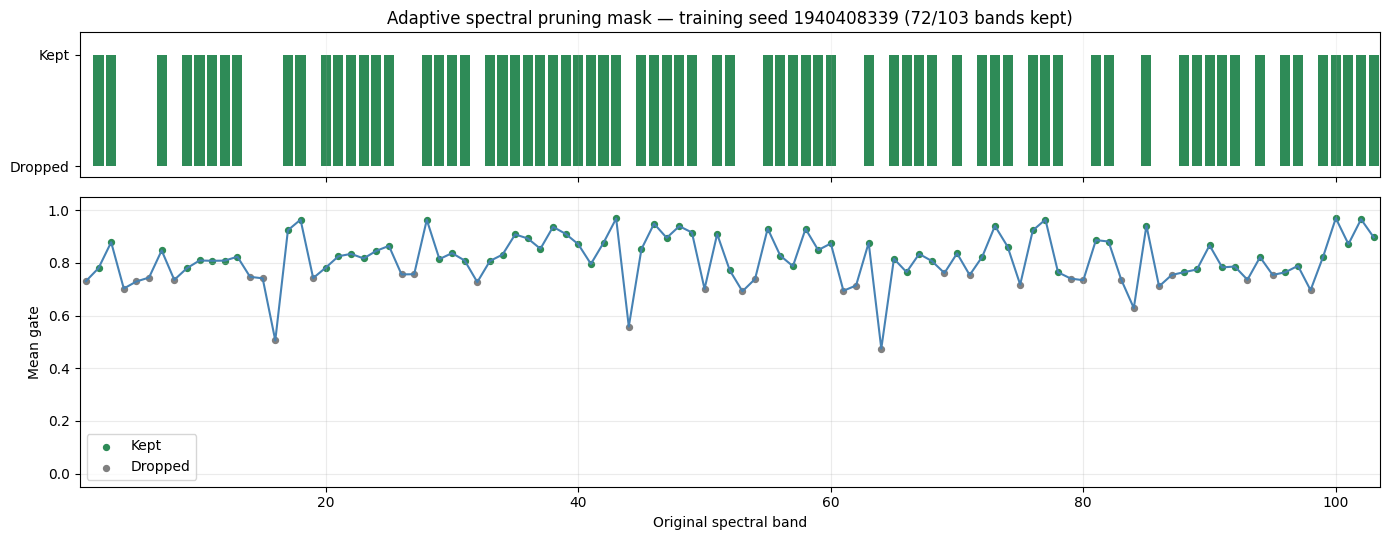

Selected checkpoint epoch: 26
Test predictions: 42641

=== Compact evaluation run 3/5 | seed 194592138 ===
Compact test evaluation seed 194592138: batch 1/1333 | samples 32/42641
Compact test evaluation seed 194592138: batch 100/1333 | samples 3200/42641
Compact test evaluation seed 194592138: batch 200/1333 | samples 6400/42641
Compact test evaluation seed 194592138: batch 300/1333 | samples 9600/42641
Compact test evaluation seed 194592138: batch 400/1333 | samples 12800/42641
Compact test evaluation seed 194592138: batch 500/1333 | samples 16000/42641
Compact test evaluation seed 194592138: batch 600/1333 | samples 19200/42641
Compact test evaluation seed 194592138: batch 700/1333 | samples 22400/42641
Compact test evaluation seed 194592138: batch 800/1333 | samples 25600/42641
Compact test evaluation seed 194592138: batch 900/1333 | samples 28800/42641
Compact test evaluation seed 194592138: batch 1000/1333 | samples 32000/42641
Compact test evaluation seed 194592138: batch 1100/13

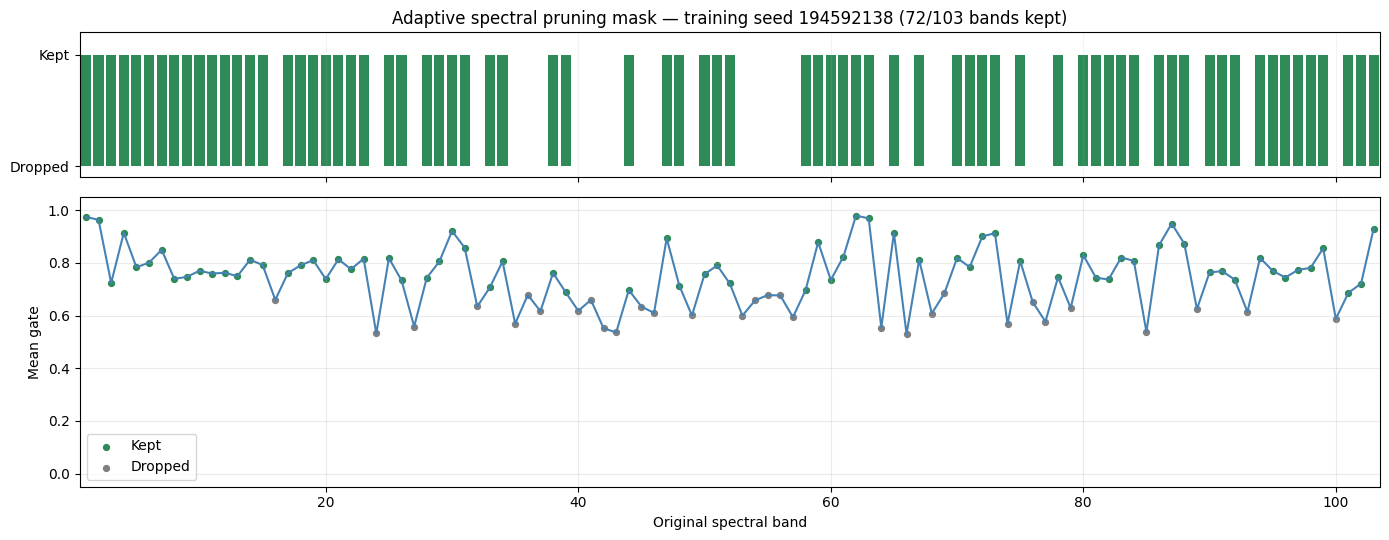

Selected checkpoint epoch: 12
Test predictions: 42641

=== Compact evaluation run 4/5 | seed 628378136 ===
Compact test evaluation seed 628378136: batch 1/1333 | samples 32/42641
Compact test evaluation seed 628378136: batch 100/1333 | samples 3200/42641
Compact test evaluation seed 628378136: batch 200/1333 | samples 6400/42641
Compact test evaluation seed 628378136: batch 300/1333 | samples 9600/42641
Compact test evaluation seed 628378136: batch 400/1333 | samples 12800/42641
Compact test evaluation seed 628378136: batch 500/1333 | samples 16000/42641
Compact test evaluation seed 628378136: batch 600/1333 | samples 19200/42641
Compact test evaluation seed 628378136: batch 700/1333 | samples 22400/42641
Compact test evaluation seed 628378136: batch 800/1333 | samples 25600/42641
Compact test evaluation seed 628378136: batch 900/1333 | samples 28800/42641
Compact test evaluation seed 628378136: batch 1000/1333 | samples 32000/42641
Compact test evaluation seed 628378136: batch 1100/13

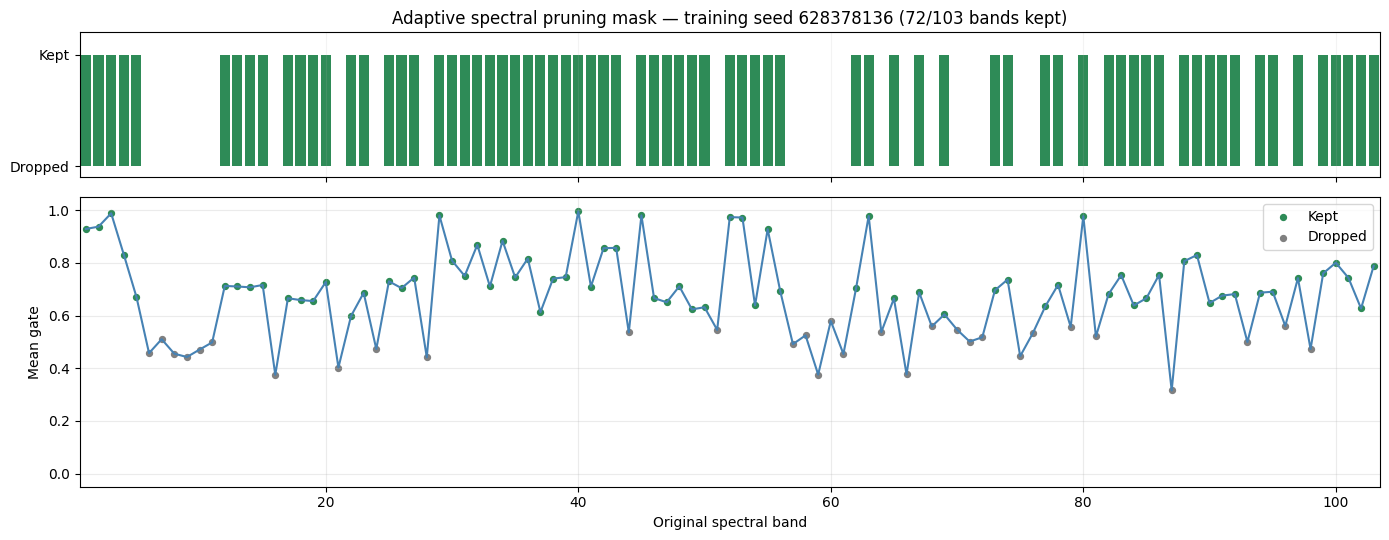

Selected checkpoint epoch: 3
Test predictions: 42641

=== Compact evaluation run 5/5 | seed 109688099 ===
Compact test evaluation seed 109688099: batch 1/1333 | samples 32/42641
Compact test evaluation seed 109688099: batch 100/1333 | samples 3200/42641
Compact test evaluation seed 109688099: batch 200/1333 | samples 6400/42641
Compact test evaluation seed 109688099: batch 300/1333 | samples 9600/42641
Compact test evaluation seed 109688099: batch 400/1333 | samples 12800/42641
Compact test evaluation seed 109688099: batch 500/1333 | samples 16000/42641
Compact test evaluation seed 109688099: batch 600/1333 | samples 19200/42641
Compact test evaluation seed 109688099: batch 700/1333 | samples 22400/42641
Compact test evaluation seed 109688099: batch 800/1333 | samples 25600/42641
Compact test evaluation seed 109688099: batch 900/1333 | samples 28800/42641
Compact test evaluation seed 109688099: batch 1000/1333 | samples 32000/42641
Compact test evaluation seed 109688099: batch 1100/133

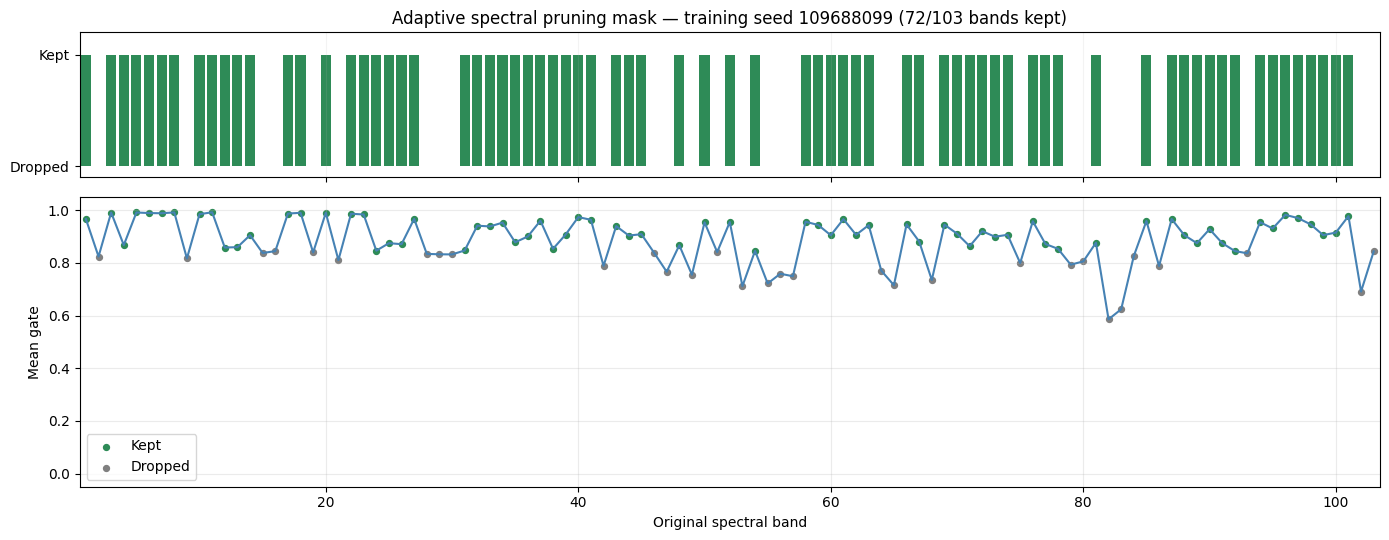

Selected checkpoint epoch: 15
Test predictions: 42641
Unpruned test evaluation seed 1496815513: batch 1/1333 | samples 32/42641
Unpruned test evaluation seed 1496815513: batch 100/1333 | samples 3200/42641
Unpruned test evaluation seed 1496815513: batch 200/1333 | samples 6400/42641
Unpruned test evaluation seed 1496815513: batch 300/1333 | samples 9600/42641
Unpruned test evaluation seed 1496815513: batch 400/1333 | samples 12800/42641
Unpruned test evaluation seed 1496815513: batch 500/1333 | samples 16000/42641
Unpruned test evaluation seed 1496815513: batch 600/1333 | samples 19200/42641
Unpruned test evaluation seed 1496815513: batch 700/1333 | samples 22400/42641
Unpruned test evaluation seed 1496815513: batch 800/1333 | samples 25600/42641
Unpruned test evaluation seed 1496815513: batch 900/1333 | samples 28800/42641
Unpruned test evaluation seed 1496815513: batch 1000/1333 | samples 32000/42641
Unpruned test evaluation seed 1496815513: batch 1100/1333 | samples 35200/42641
Unpr

In [16]:
# Evaluate the compact model and, when requested, the full-band baseline.
evaluation_runs = []
for run_index, run in enumerate(training_runs, start=1):
    training_seed = run["seed"]
    print(
        f"\n=== Compact evaluation run {run_index}/{len(training_runs)} "
        f"| seed {training_seed} ==="
    )
    model = build_configured_model().to(DEVICE)

    if ARCHITECTURE.uses_adaptive_pruning:
        mask_checkpoint = torch.load(
            run["mask_checkpoint_path"], map_location=DEVICE, weights_only=False
        )
        model.load_state_dict(mask_checkpoint["model_state_dict"])
        selected_band_indices = torch.as_tensor(
            mask_checkpoint["selected_band_indices"], dtype=torch.long
        )
        mean_band_gates = torch.as_tensor(mask_checkpoint["mean_band_gates"])
        compact_model = build_compact_pruned_model(
            model, selected_band_indices
        ).to(DEVICE)
        if run["configuration"].get("pruning_finetune_epochs", 0) > 0:
            checkpoint = torch.load(
                run["checkpoint_path"], map_location=DEVICE, weights_only=False
            )
            compact_model.load_state_dict(checkpoint["model_state_dict"])
        else:
            checkpoint = mask_checkpoint
        targets, predictions = predict_classes(
            compact_model,
            test_loader,
            DEVICE,
            progress_every=EVALUATION_PROGRESS_EVERY,
            progress_label=f"Compact test evaluation seed {training_seed}",
        )
        evaluation_result = {
            "checkpoint": checkpoint,
            "targets": targets,
            "predictions": predictions,
            "metrics": calculate_classification_metrics(
                targets, predictions, NUM_CLASSES
            ),
            "selected_band_indices": selected_band_indices.tolist(),
            "mean_band_gates": mean_band_gates.tolist(),
        }
        run["configuration"].update({
            "pruned_band_count": len(selected_band_indices),
            "selected_band_indices": selected_band_indices.tolist(),
            "mean_band_gates": mean_band_gates.tolist(),
        })
        plot_pruning_mask(
            mean_band_gates.numpy(),
            selected_band_indices.numpy(),
            run_label=f"training seed {training_seed}",
        )
        del compact_model
    else:
        evaluation_result = evaluate_checkpoint(
            model,
            test_loader,
            run["checkpoint_path"],
            DEVICE,
            NUM_CLASSES,
            progress_every=EVALUATION_PROGRESS_EVERY,
            progress_label=f"Test evaluation seed {training_seed}",
        )

    assert len(evaluation_result["targets"]) == len(test_dataset)
    evaluation_runs.append({**run, "evaluation_result": evaluation_result})
    print("Selected checkpoint epoch:", evaluation_result["checkpoint"]["epoch"])
    print("Test predictions:", len(evaluation_result["predictions"]))
    del model

baseline_evaluation_runs = []
if COMPARE_WITH_UNPRUNED and ARCHITECTURE.uses_adaptive_pruning:
    for run in baseline_training_runs:
        baseline_model = build_model(
            ModelArchitecture.CNN_TRANSFORMER_CSA,
            **MODEL_ARGUMENTS,
        ).to(DEVICE)
        baseline_evaluation_result = evaluate_checkpoint(
            baseline_model,
            test_loader,
            run["checkpoint_path"],
            DEVICE,
            NUM_CLASSES,
            progress_every=EVALUATION_PROGRESS_EVERY,
            progress_label=f"Unpruned test evaluation seed {run['seed']}",
        )
        baseline_evaluation_runs.append({
            **run,
            "evaluation_result": baseline_evaluation_result,
        })
        del baseline_model

    assert [run["seed"] for run in evaluation_runs] == [
        run["seed"] for run in baseline_evaluation_runs
    ]

### Test Metrics and Optional Full-Band Comparison

Reports compact-model test metrics and, when enabled, paired results against an independently trained full-band CTA-CSA baseline.

In [17]:
# Print compact and optional full-band test results and save their reports.
for run in evaluation_runs:
    metrics = run["evaluation_result"]["metrics"]
    print(f"\nCompact model | training seed {run['seed']}")
    print(f"OA: {metrics['overall_accuracy']:.4f}")
    print(f"AA: {metrics['average_accuracy']:.4f}")
    print(f"Kappa: {metrics['kappa']:.4f}")
    report = build_evaluation_report(
        run["configuration"], run["checkpoint_path"],
        run["evaluation_result"], class_names,
    )
    if SAVE_EVALUATION_REPORT:
        report_path = project_root / "outputs" / "results" / f"{run['checkpoint_path'].stem}.json"
        save_evaluation_report(report_path, report)

aggregate_metrics = aggregate_classification_metrics(
    [run["evaluation_result"]["metrics"] for run in evaluation_runs]
)

if baseline_evaluation_runs:
    for run in baseline_evaluation_runs:
        metrics = run["evaluation_result"]["metrics"]
        print(f"\nFull-band CTA-CSA | training seed {run['seed']}")
        print(f"OA: {metrics['overall_accuracy']:.4f}")
        print(f"AA: {metrics['average_accuracy']:.4f}")
        print(f"Kappa: {metrics['kappa']:.4f}")
        report = build_evaluation_report(
            run["configuration"], run["checkpoint_path"],
            run["evaluation_result"], class_names,
        )
        if SAVE_EVALUATION_REPORT:
            report_path = project_root / "outputs" / "results" / f"{run['checkpoint_path'].stem}.json"
            save_evaluation_report(report_path, report)
    baseline_aggregate_metrics = aggregate_classification_metrics(
        [run["evaluation_result"]["metrics"] for run in baseline_evaluation_runs]
    )
else:
    baseline_aggregate_metrics = None

# Save one aggregate report, including the baseline only when it was evaluated.
if TRAINING_SEED_MODE != TrainingSeedMode.ONE_FIXED_TRAIN_SEED:
    aggregate_configuration = dict(evaluation_runs[0]["configuration"])
    aggregate_configuration.pop("training_seed", None)
    aggregate_configuration.update({
        "num_seeds": len(training_seeds),
        "training_seeds": training_seeds,
        "compare_with_unpruned": bool(baseline_evaluation_runs),
    })
    aggregate_report = {
        "configuration": aggregate_configuration,
        "runs": [
            {
                "training_seed": run["seed"],
                "checkpoint_path": str(run["checkpoint_path"]),
                "best_epoch": run["training_result"]["best_epoch"],
                "validation_loss": run["training_result"]["best_validation_loss"],
                "compact_test_metrics": run["evaluation_result"]["metrics"],
            }
            for run in evaluation_runs
        ],
        "compact_model_aggregate": aggregate_metrics,
    }
    if baseline_aggregate_metrics is not None:
        aggregate_report["unpruned_baseline_aggregate"] = baseline_aggregate_metrics
    seed_collection = (
        "fixed" if TRAINING_SEED_MODE == TrainingSeedMode.MULTI_FIXED_TRAIN_SEED
        else "random"
    )
    checkpoint_stem = evaluation_runs[0]["checkpoint_path"].stem
    compact_suffix = "_compact" if checkpoint_stem.endswith("_compact") else ""
    aggregate_name = (
        f"{seed_collection}{len(training_seeds)}_"
        f"{training_seeds[0]}-{training_seeds[-1]}{compact_suffix}"
    )
    aggregate_stem = checkpoint_stem.replace(
        f"train{training_seeds[0]}{compact_suffix}", aggregate_name
    )
    aggregate_path = project_root / "outputs" / "results" / f"{aggregate_stem}.json"
    if SAVE_EVALUATION_REPORT:
        save_evaluation_report(aggregate_path, aggregate_report)

if baseline_evaluation_runs:
    comparison_metrics = ("overall_accuracy", "average_accuracy", "kappa")
    paired_runs = []
    for compact_run, baseline_run in zip(evaluation_runs, baseline_evaluation_runs):
        compact_metrics = compact_run["evaluation_result"]["metrics"]
        baseline_metrics = baseline_run["evaluation_result"]["metrics"]
        paired_runs.append({
            "seed": compact_run["seed"],
            "compact": {k: float(compact_metrics[k]) for k in comparison_metrics},
            "full_band": {k: float(baseline_metrics[k]) for k in comparison_metrics},
            "delta_compact_minus_full_band": {
                k: float(compact_metrics[k] - baseline_metrics[k])
                for k in comparison_metrics
            },
        })
    paired_delta_summary = {}
    for metric_name in comparison_metrics:
        deltas = np.asarray([
            run["delta_compact_minus_full_band"][metric_name]
            for run in paired_runs
        ])
        paired_delta_summary[metric_name] = {
            "mean": float(deltas.mean()),
            "std": float(deltas.std(ddof=1)) if len(deltas) > 1 else 0.0,
        }
    print("\nPaired test metrics: compact vs full-band CTA-CSA")
    for run in paired_runs:
        print(
            f"seed {run['seed']}: "
            f"OA {run['compact']['overall_accuracy']:.4f} vs {run['full_band']['overall_accuracy']:.4f}; "
            f"AA {run['compact']['average_accuracy']:.4f} vs {run['full_band']['average_accuracy']:.4f}; "
            f"Kappa {run['compact']['kappa']:.4f} vs {run['full_band']['kappa']:.4f}"
        )
    for metric_name, label in (("overall_accuracy", "OA"), ("average_accuracy", "AA"), ("kappa", "Kappa")):
        summary = paired_delta_summary[metric_name]
        print(f"Mean compact-minus-full-band {label}: {summary['mean']:+.4f} ± {summary['std']:.4f}")
    comparison_report = {
        "dataset": "Pavia University",
        "split_seed": SPLIT_SEED,
        "training_seeds": training_seeds,
        "compact_model": {
            "architecture": ARCHITECTURE.value,
            "pruning_percentage": PRUNING_PERCENTAGE,
            "training_epochs": EPOCHS,
            "compact_finetune_epochs": PRUNING_FINETUNE_EPOCHS,
        },
        "full_band_baseline": {
            "architecture": ModelArchitecture.CNN_TRANSFORMER_CSA.value,
            "training_epochs": BASELINE_EPOCHS,
            "trained_from_scratch": True,
        },
        "paired_delta_compact_minus_full_band": paired_delta_summary,
        "runs": paired_runs,
    }
    comparison_path = (
        project_root / "outputs" / "results"
        / f"compact_vs_unpruned_{PRUNING_PERCENTAGE:g}pct_{len(training_seeds)}seeds.json"
    )
    if SAVE_EVALUATION_REPORT:
        save_evaluation_report(comparison_path, comparison_report)


Compact model | training seed 1496815513
OA: 0.8633
AA: 0.9089
Kappa: 0.8247

Compact model | training seed 1940408339
OA: 0.8536
AA: 0.8868
Kappa: 0.8117

Compact model | training seed 194592138
OA: 0.8431
AA: 0.8877
Kappa: 0.7999

Compact model | training seed 628378136
OA: 0.8773
AA: 0.8898
Kappa: 0.8399

Compact model | training seed 109688099
OA: 0.8652
AA: 0.8972
Kappa: 0.8260

Full-band CTA-CSA | training seed 1496815513
OA: 0.8701
AA: 0.8872
Kappa: 0.8305

Full-band CTA-CSA | training seed 1940408339
OA: 0.8840
AA: 0.9058
Kappa: 0.8503

Full-band CTA-CSA | training seed 194592138
OA: 0.8626
AA: 0.8949
Kappa: 0.8235

Full-band CTA-CSA | training seed 628378136
OA: 0.9178
AA: 0.9190
Kappa: 0.8918

Full-band CTA-CSA | training seed 109688099
OA: 0.8891
AA: 0.8792
Kappa: 0.8521

Paired test metrics: compact vs full-band CTA-CSA
seed 1496815513: OA 0.8633 vs 0.8701; AA 0.9089 vs 0.8872; Kappa 0.8247 vs 0.8305
seed 1940408339: OA 0.8536 vs 0.8840; AA 0.8868 vs 0.9058; Kappa 0.8117 v

### Aggregated Test Results

Mean and sample standard deviation across seeds for the compact model and, when enabled, the full-band baseline.

In [18]:
# Show aggregate test metrics before the confusion matrices.
def print_aggregate_results(label, metrics):
    print(f"\n{label} - {metrics['num_runs']} seeds")
    for metric_label, metric_name in (
        ("OA", "overall_accuracy"),
        ("AA", "average_accuracy"),
        ("Kappa", "kappa"),
    ):
        summary = metrics[metric_name]
        print(f"{metric_label}: {summary['mean']:.4f} ± {summary['std']:.4f}")

if baseline_aggregate_metrics is not None:
    print_aggregate_results("Full-band CTA-CSA", baseline_aggregate_metrics)
print_aggregate_results("Compact pruned model", aggregate_metrics)


Full-band CTA-CSA - 5 seeds
OA: 0.8847 ± 0.0213
AA: 0.8972 ± 0.0156
Kappa: 0.8496 ± 0.0266

Compact pruned model - 5 seeds
OA: 0.8605 ± 0.0129
AA: 0.8941 ± 0.0092
Kappa: 0.8205 ± 0.0152


### Aggregate Confusion Matrices

Plots the existing aggregate matrices for the compact model and, when enabled, the full-band baseline.

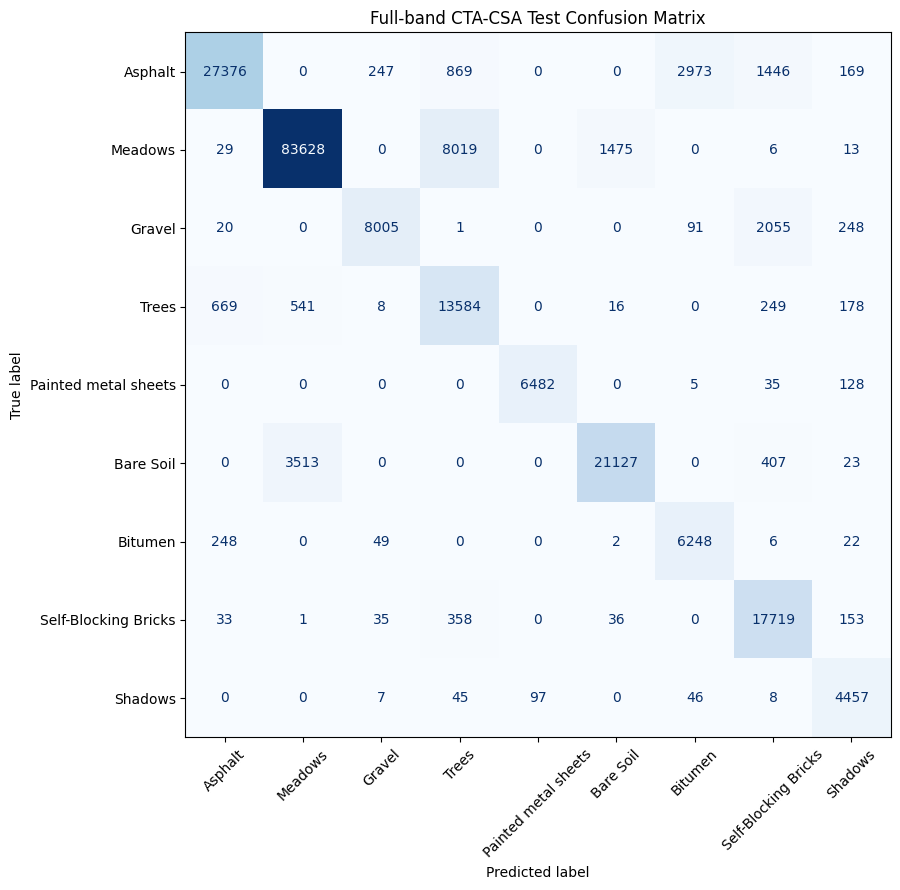

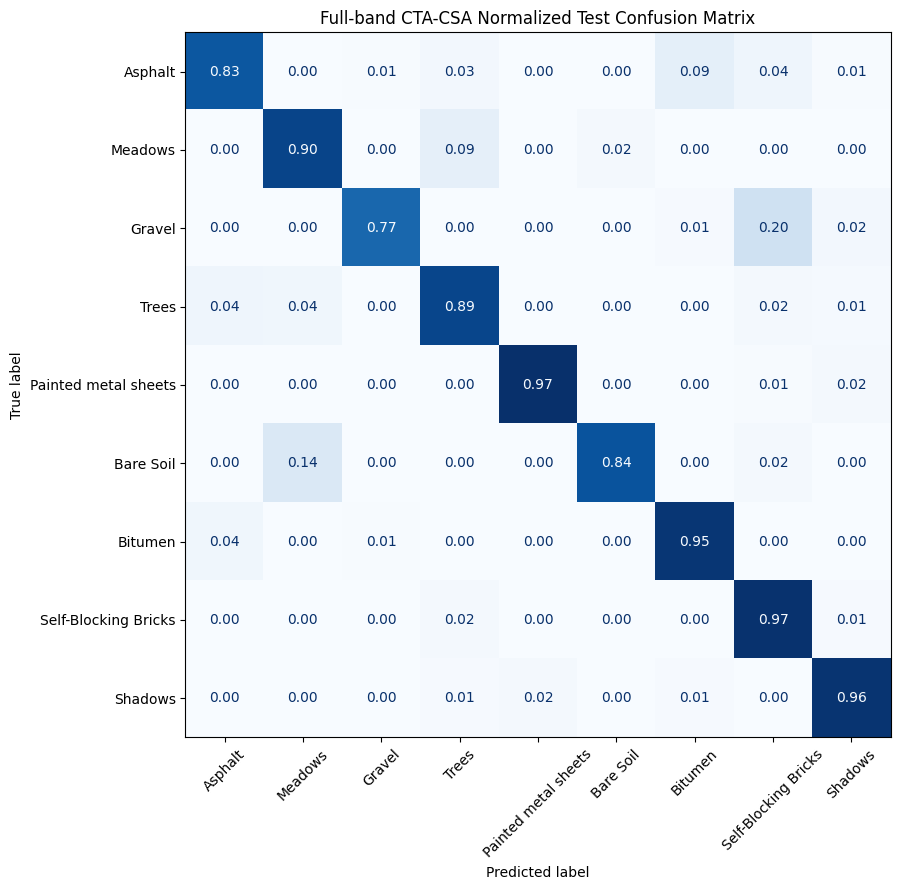

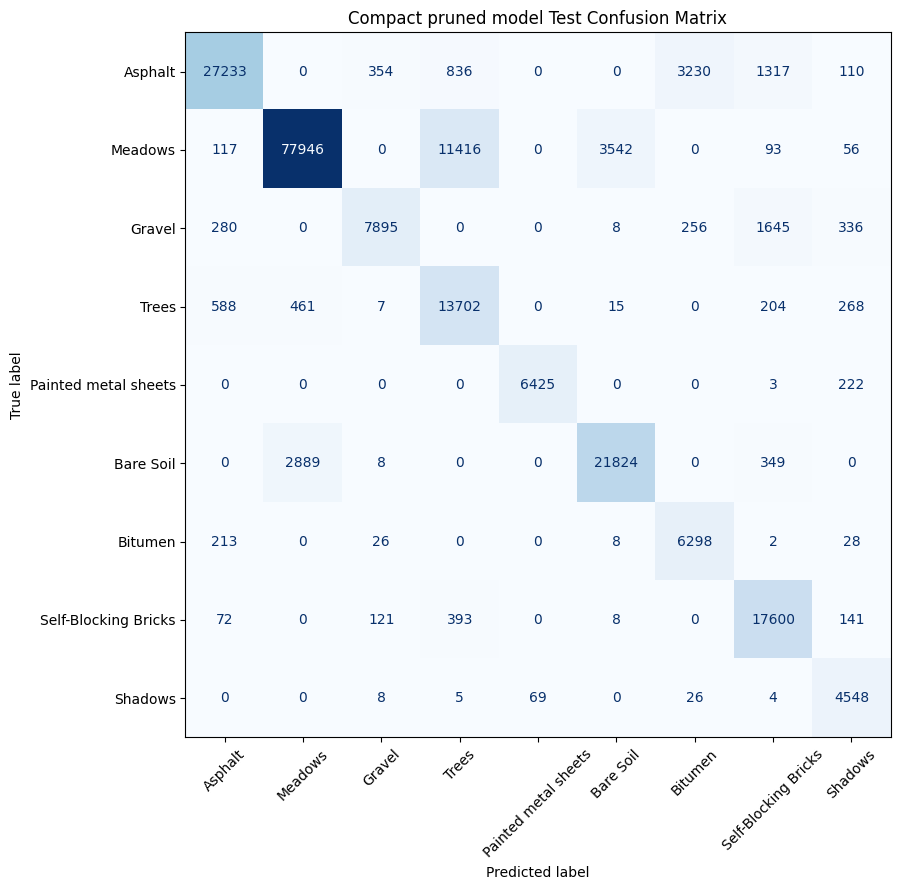

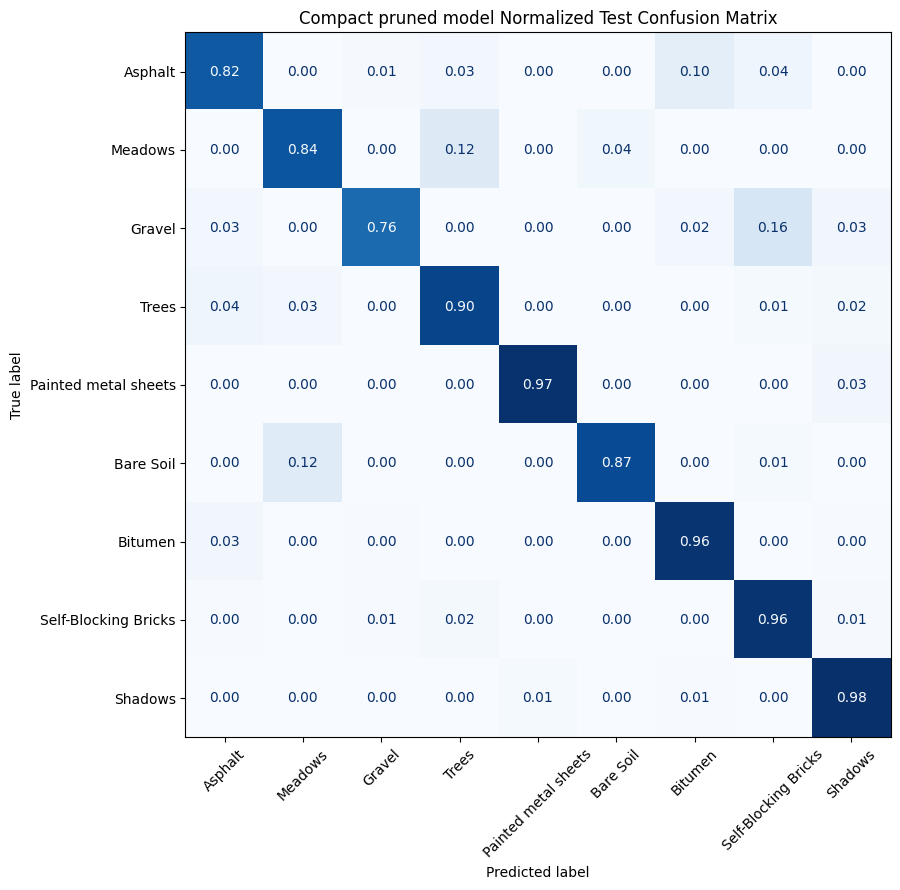

In [19]:
# Plot the existing aggregate confusion matrices for available models.
display_names = [class_names[label] for label in LABELED_CLASS_IDS]

if baseline_aggregate_metrics is not None:
    baseline_confusion = baseline_aggregate_metrics["confusion_matrix_sum"]
    baseline_name = "Full-band CTA-CSA"
    plot_confusion_matrix(baseline_confusion, display_names, baseline_name)
    plot_confusion_matrix(
        baseline_confusion, display_names, baseline_name, normalized=True
    )

compact_confusion = aggregate_metrics["confusion_matrix_sum"]
plot_confusion_matrix(compact_confusion, display_names, "Compact pruned model")
plot_confusion_matrix(
    compact_confusion, display_names, "Compact pruned model", normalized=True
)

### Classification Maps for a Matched Seed

Shows the compact model map and, when enabled, the full-band map for the same seed.

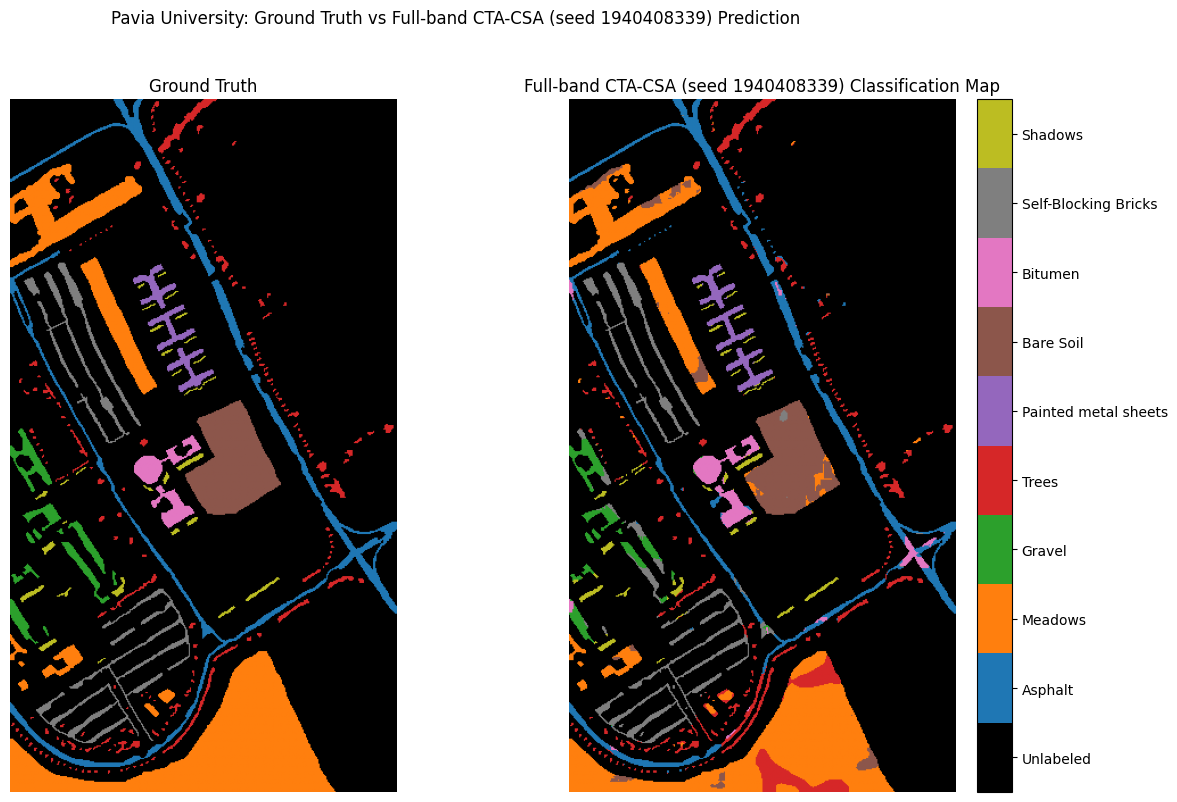


Building compact classification map | seed 1940408339


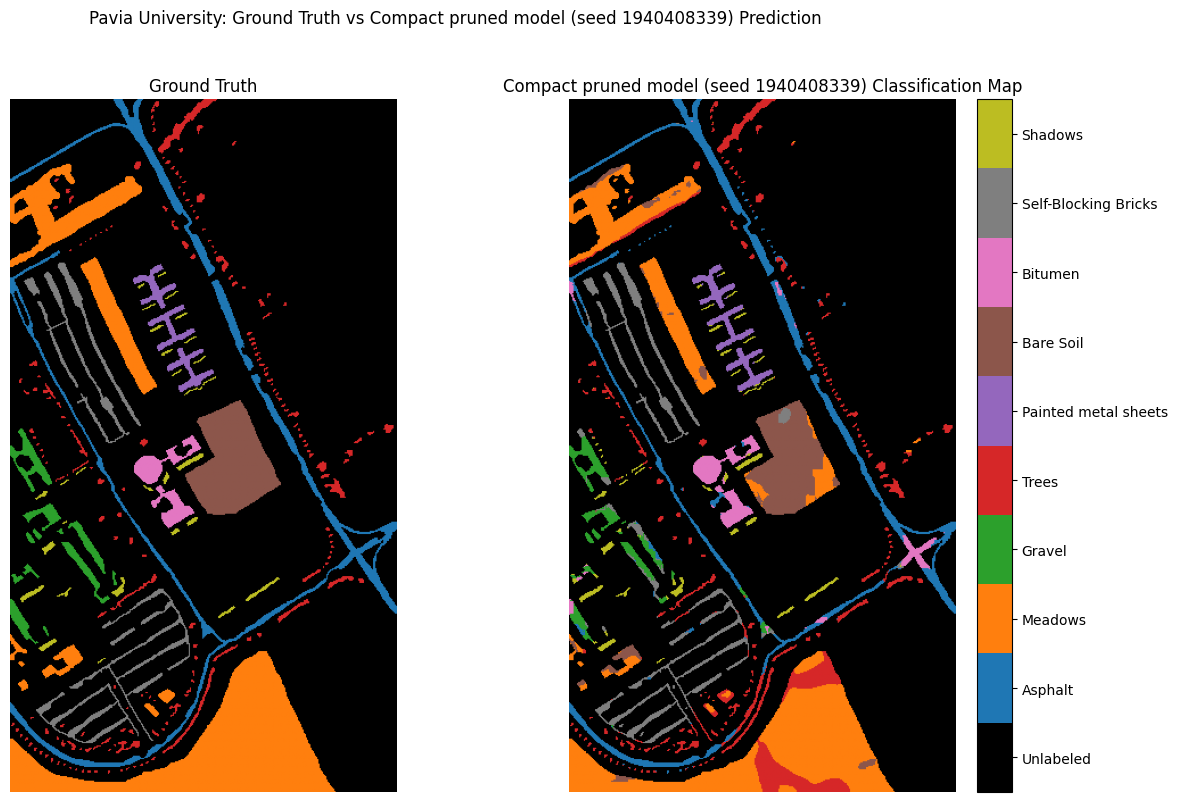

Mapped labeled pixels: 42776
Unlabeled pixels kept as background: 164624


In [20]:
# Map the best compact run and, when available, its matched full-band run.
labeled_mask = ground_truth != PaviaClass.UNLABELED
if baseline_evaluation_runs:
    selected_run = min(
        baseline_evaluation_runs,
        key=lambda run: run["training_result"]["best_validation_loss"],
    )
    training_seed = selected_run["seed"]
    baseline_model = build_model(
        ModelArchitecture.CNN_TRANSFORMER_CSA,
        **MODEL_ARGUMENTS,
    ).to(DEVICE)
    baseline_checkpoint = torch.load(
        selected_run["checkpoint_path"], map_location=DEVICE, weights_only=False
    )
    baseline_model.load_state_dict(baseline_checkpoint["model_state_dict"])
    baseline_map = build_classification_map(
        baseline_model, DEVICE, ground_truth, padded_cube, split_tables,
        selected_run["evaluation_result"]["predictions"],
        patch_size=PATCH_SIZE, num_classes=NUM_CLASSES,
        batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    )
    plot_classification_map(
        ground_truth, baseline_map, class_names, NUM_CLASSES,
        f"Full-band CTA-CSA (seed {training_seed})",
    )
    del baseline_model
    compact_run = next(run for run in evaluation_runs if run["seed"] == training_seed)
else:
    compact_run = min(
        evaluation_runs,
        key=lambda run: run["training_result"]["best_validation_loss"],
    )
    training_seed = compact_run["seed"]

print(f"\nBuilding compact classification map | seed {training_seed}")
if ARCHITECTURE.uses_adaptive_pruning:
    mask_checkpoint = torch.load(
        compact_run["mask_checkpoint_path"], map_location=DEVICE, weights_only=False
    )
    selected_band_indices = torch.as_tensor(
        mask_checkpoint["selected_band_indices"], dtype=torch.long
    )
    compact_source_model = build_configured_model().to(DEVICE)
    compact_source_model.load_state_dict(mask_checkpoint["model_state_dict"])
    compact_model = build_compact_pruned_model(
        compact_source_model, selected_band_indices
    ).to(DEVICE)
    del compact_source_model
    if compact_run["configuration"].get("pruning_finetune_epochs", 0) > 0:
        compact_checkpoint = torch.load(
            compact_run["checkpoint_path"], map_location=DEVICE, weights_only=False
        )
        compact_model.load_state_dict(compact_checkpoint["model_state_dict"])
else:
    compact_model = build_configured_model().to(DEVICE)
    compact_checkpoint = torch.load(
        compact_run["checkpoint_path"], map_location=DEVICE, weights_only=False
    )
    compact_model.load_state_dict(compact_checkpoint["model_state_dict"])

compact_map = build_classification_map(
    compact_model, DEVICE, ground_truth, padded_cube, split_tables,
    compact_run["evaluation_result"]["predictions"],
    patch_size=PATCH_SIZE, num_classes=NUM_CLASSES,
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
)
plot_classification_map(
    ground_truth, compact_map, class_names, NUM_CLASSES,
    f"Compact pruned model (seed {training_seed})",
)
del compact_model
print("Mapped labeled pixels:", np.count_nonzero(labeled_mask))
print("Unlabeled pixels kept as background:", (~labeled_mask).sum())